# Responsible Innovation in National AI Policies
### Adoption, legal status, governance capacity and the actualization of responsible-innovation commitments

**Target journal:** *Technological Forecasting and Social Change* (Elsevier)
**Anchor paper:** *Responsible AI for responsible innovation in Chinese manufacturing: From the affordance–actualization theory* (2025), DOI: 10.1016/j.techfore.2025.124349
**Version:** v1.2.0 (revised analysis; see *Revision notes* below)

**Theoretical lens.** Responsible innovation (RI) is operationalised with the four dimensions of Stilgoe, Owen & Macnaghten (2013): *anticipation, reflexivity, inclusion, responsiveness*. Following the affordance–actualization perspective of the anchor paper, lifted from the firm to the state level, a national AI **strategy articulates** the affordances of AI, while **binding instruments, dedicated institutions, obligations and resourced targets actualize** them.

| RQ | Question | Main exhibits |
|---|---|---|
| **RQ1** | Which RI dimensions do national AI policy instruments articulate, and does the RI profile shift from ethics-oriented reflexivity in non-binding instruments to risk- and accountability-oriented responsiveness in binding ones? | Figures 1.1–1.2, Tables 1.1–1.4 |
| **RQ2** | Is government effectiveness associated with national AI strategy adoption, and is this association conditional on income level? | Figures 2.1–2.2, Tables 2.1–2.4 |
| **RQ3** | *As proposed:* among countries with AI policies, does governance capacity predict the actualization of strategic commitments into binding instruments, or are the two decoupled? *As analysed (cross-sectional):* among countries with a recorded AI policy, is government effectiveness associated with having an enacted national binding measure? | Figures 3.1–3.2, Tables 3.1–3.4 |
| **RQ4** | How have legal status and RI profile changed between the pre-generative-AI (2017–2022) and generative-AI (2023+) periods? | Figures 4.1–4.2, Tables 4.1–4.4 |

**Scope of inference.** All analyses are cross-sectional and observational. Country-level results are *associations* between governance indicators and the policy instruments *recorded by the AI Policy Tracker*; they do not trace individual strategies into law and do not establish causal effects. RI content is coded from the Tracker's short plain-language summaries, not from full policy texts.

**Revision notes (v1.1.0 and v1.2.0, responding to two rounds of technical review).**
1. *Validation.* The validation sample (Table S5) is coded by an LLM-assisted rater blind to the dictionary output; dictionary-vs-rater agreement and Cohen's κ are reported per code and per dimension (Table 1.2). The notebook also computes coder A–B and dictionary–consensus κ as soon as human coding files are supplied. Dictionary codes remain the single measurement used for all instruments; validation labels never replace them. One word-boundary error (*commissioned* matched as *commission*) was corrected in the codebook.
2. *Legal status.* Instruments are classified as **enacted binding**, **draft binding** (proposed bills/drafts flagged binding by the Tracker) and **non-binding**. RQ1 and RQ4 compare enacted binding with non-binding instruments; the Tracker flag is kept only as a labelled sensitivity. Country-clustered, summary-length-adjusted models address non-independence and text-length differences.
3. *RQ2.* The GE × income interaction (models, joint LR test, income-specific slopes with 95 % CIs) is re-estimated for pre-period GE and Regulatory Quality. Odds ratios are labelled *per 1-unit increase in the WGI estimate*.
4. *RQ3.* Wording restricted to cross-sectional associations; stage renamed *Recorded policy, no enacted national binding measure*; strategy × law cross-tabulation and chronology added; Firth models report convergence, rank checks and profile penalised-likelihood CIs; the EU AI Act is reported as a shared supranational measure.
5. *RQ4.* Reference-date source recorded per instrument; missing dates reported by type and legal status; the main comparison uses complete years (2017–2022 vs 2023–2025) with partial 2026 as a sensitivity; figures labelled as recorded instruments by reference year.
6. *Replication.* Exact input snapshot with SHA-256 checksums, explicit input paths, pinned environment, omnibus tests exported, eight figures as planned in the proposal.
7. *v1.2.0 – procedural stage.* Procedural stage (proposal vs finalized) is coded separately from the binding flag. RQ1 compares enacted binding measures with **finalized non-binding** instruments (proposals excluded from both groups); including proposals is a labelled sensitivity. RQ4 reports the share of proposals separately and a finalized-only sensitivity.
8. *v1.2.0 – validation (deviation from the proposal).* The planned two-coder human validation was not carried out; Table 1.2 reports dictionary-vs-LLM-assisted-rater reliability only, and this is stated as a limitation. Infrastructure for adding human coding later: The human coding sheet uses randomized coding IDs and shows the summary text only; the loader rejects duplicate IDs, missing summaries and non-binary values; human validation is reported as complete only when coder A, coder B **and** an adjudicated consensus file are present. The LLM-assisted rating procedure (model, prompt, date) is documented in `validation/llm_rater_procedure.md`.
9. *v1.2.0 – reporting.* RQ3 is analysed and reported as the cross-sectional question above; key findings report unadjusted and country-clustered, length-adjusted estimates side by side for RQ1 and RQ4.

No machine learning is used in the analysis: descriptive statistics, rule-based content coding, cross-tabulations and classical tests.

## Step 1 · Environment set-up
**What this cell does:** imports the libraries, defines the output folders (`/kaggle/working/outputs` on Kaggle, `./outputs` elsewhere), sets a consistent publication style (colour-blind-checked palette), defines helpers that display and save every exhibit (figures as PDF + 300-dpi PNG, tables as CSV) and writes the software versions to `outputs/session_info.txt`.
**Methodological step:** reproducibility infrastructure used by every RQ.

In [1]:
import os, re, sys, json, zipfile, shutil, hashlib, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.transforms as mtrans
import scipy
from scipy import stats, optimize
from scipy.special import expit
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import sklearn
from sklearn.metrics import cohen_kappa_score
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
SEED = 2026
rng = np.random.default_rng(SEED)

# ---- output folders --------------------------------------------------------
OUT = Path("/kaggle/working/outputs") if Path("/kaggle/working").exists() else Path("outputs")
if OUT.exists():
    shutil.rmtree(OUT)                       # clean run: never mix outputs of different runs
FIG, TAB = OUT / "figures", OUT / "tables"
for d in (FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)

# ---- session info (pinned versions are listed in requirements.txt) ----------
session = {"python": platform.python_version(), "platform": platform.platform(),
           "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
           "statsmodels": statsmodels.__version__, "matplotlib": mpl.__version__,
           "scikit-learn": sklearn.__version__}
(OUT / "session_info.txt").write_text("\n".join(f"{k}: {v}" for k, v in session.items()), encoding="utf-8")
print(session)

# ---- publication style -------------------------------------------------------
COL = {
    "binding": "#2a78d6",      # enacted binding
    "draft": "#9ec5f2",        # draft binding
    "nonbinding": "#eb6834",   # non-binding
    "post": "#1baf7a", "pre": "#8f8e88", "none": "#b5b4ae",
    "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#8a8984", "grid": "#e6e5e0",
}
INCOME_SEQ = ["#9ec5f2", "#4f93e0", "#1d5aa8"]
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42,
    "font.family": "DejaVu Sans", "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.labelsize": 9, "axes.labelcolor": COL["ink2"], "axes.edgecolor": COL["muted"],
    "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": COL["grid"], "grid.linewidth": 0.6,
    "xtick.color": COL["ink2"], "ytick.color": COL["ink2"], "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.frameon": False, "legend.fontsize": 8.5, "text.color": COL["ink"],
    "lines.linewidth": 2, "axes.axisbelow": True, "svg.hashsalt": "ai-ri",
})
PDF_META = {"CreationDate": None, "ModDate": None}   # deterministic PDF output

def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight", metadata=PDF_META)
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", metadata={"Software": None})
    plt.show()
    print(f"saved -> {FIG / (name + '.pdf')}")

def save_table(df, name, index=False, show=True):
    df.to_csv(TAB / f"{name}.csv", index=index)
    if show:
        display(df)
    print(f"saved -> {TAB / (name + '.csv')}")

def fmt_p(p):
    if pd.isna(p): return "n/a"
    return "<0.001" if p < 0.001 else f"{p:.3f}"

def pstr(p, sym="p"):
    if pd.isna(p): return f"{sym} = n/a"
    return f"{sym} < 0.001" if p < 0.001 else f"{sym} = {p:.3f}"

def stars(p):
    if pd.isna(p): return ""
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""

def bh(p):
    p = np.asarray(p, float); out = np.full(len(p), np.nan); ok = ~np.isnan(p)
    if ok.any():
        out[ok] = multipletests(p[ok], method="fdr_bh")[1]
    return out

print("Output folder:", OUT.resolve())

{'python': '3.13.18', 'platform': 'Linux-6.18.44-fc-v310-x86_64-with-glibc2.39', 'numpy': '2.5.3', 'pandas': '3.0.5', 'scipy': '1.18.1', 'statsmodels': '0.15.0', 'matplotlib': '3.11.2', 'scikit-learn': '1.9.1'}
Output folder: /home/claude/run12/outputs


## Step 1b · Input files: explicit paths and checksum verification
**What this cell does:** looks for the three source files under their **exact original names** in `./data` (repository snapshot) and, on Kaggle, in `/kaggle/input/**`. File-name matching is case-insensitive, and a pattern fallback is used only if an exact name is absent (with a warning). The SHA-256 checksum of each file is compared with the archived snapshot used for the published results (`data/checksums.sha256`). A mismatch is reported, not hidden, because a newer download of the Tracker can contain different records. Output: *Table S1c – input provenance*.
**Methodological step:** data acquisition (Step 1).

In [2]:
DATA_DIRS = [Path("data"), Path("/kaggle/input"), Path(".")]
INPUTS = {   # key: (exact original file name, fallback pattern, source URL)
    "policies": ("policies.csv", r"policies.*\.csv$", "https://aipolicytracker.org/open-data/policies.csv"),
    "jurisdictions": ("jurisdictions.csv", r"jurisdictions.*\.csv$", "https://aipolicytracker.org/open-data/jurisdictions.csv"),
    "wgi": ("WGI 2026 Governance Estimates and Scores (1996-2025).xlsx", r"wgi.*\.xlsx$",
            "https://datacatalogfiles.worldbank.org/ddh-published/0038026/DR0095947/"
            "WGI%202026%20Governance%20Estimates%20and%20Scores%20(1996-2025).xlsx"),
}

def _candidates():
    for d in DATA_DIRS:
        if d.exists():
            for p in sorted(d.rglob("*")):
                if p.is_file() and OUT.resolve() not in p.resolve().parents:
                    yield p

def locate(key):
    exact, pattern, _ = INPUTS[key]
    files = list(_candidates())
    hits = [p for p in files if p.name.lower() == exact.lower()]
    if hits:
        return hits[0], "exact name"
    hits = [p for p in files if re.search(pattern, p.name, flags=re.I)]
    if hits:
        print(f"WARNING: {exact!r} not found; using {hits[0].name!r} (pattern match).")
        return hits[0], "pattern match"
    raise FileNotFoundError(f"{exact!r} not found in {DATA_DIRS}. Download it from {INPUTS[key][2]}")

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

ARCHIVED = {}
for d in DATA_DIRS:
    f = d / "checksums.sha256"
    if f.exists():
        for line in f.read_text(encoding="utf-8").splitlines():
            if line.strip():
                digest, name = line.split(None, 1)
                ARCHIVED[name.strip().lstrip("*")] = digest
        break

PATHS, prov = {}, []
for key, (exact, _, url) in INPUTS.items():
    p, how = locate(key)
    PATHS[key] = p
    digest = sha256(p)
    match = ARCHIVED.get(exact)
    prov.append([key, exact, str(p), how, p.stat().st_size, digest,
                 "n/a (no checksum file)" if match is None else ("yes" if match == digest else "NO – different snapshot"), url])
provenance = pd.DataFrame(prov, columns=["input", "original_file_name", "path_used", "matched_by", "bytes",
                                         "sha256", "matches_archived_snapshot", "source_url"])
save_table(provenance, "TableS1c_input_provenance")
POL_PATH, JUR_PATH, WGI_PATH = PATHS["policies"], PATHS["jurisdictions"], PATHS["wgi"]

,input,original_file_name,path_used,matched_by,bytes,sha256,matches_archived_snapshot,source_url
0,policies,policies.csv,data/policies.csv,exact name,244683,13fdcc12c0a9065ff8f0931518dcc2a350d65f630ba92cccc69553e1301558bc,yes,https://aipolicytracker.org/open-data/policies.csv
1,jurisdictions,jurisdictions.csv,data/jurisdictions.csv,exact name,269943,807e6f83cb0921b9cdfc4cff4307969f2f7d1219ebe90f677fab140b0685557a,yes,https://aipolicytracker.org/open-data/jurisdictions.csv
2,wgi,WGI 2026 Governance Estimates and Scores (1996-2025).xlsx,data/WGI 2026 Governance Estimates and Scores (1996-2025).xlsx,exact name,10958369,8e4754bda8b2be0b36d172c18a4caa634cb36fddd54145d16ab7316d22b3542c,yes,https://datacatalogfiles.worldbank.org/ddh-published/0038026/DR0095947/WGI%2...


saved -> outputs/tables/TableS1c_input_provenance.csv


## Step 2 · Load and audit the source data
**What this cell does:** loads the AI Policy Tracker *Policies* and *Jurisdictions* tables and the Government Effectiveness (`ge`) and Regulatory Quality (`rq`) sheets of the WGI workbook, and reports size, coverage and missingness of the fields used later.
**Methodological step:** data audit (Step 2). Output: *Table S1a – data audit*.

In [3]:
pol = pd.read_csv(POL_PATH)
jur = pd.read_csv(JUR_PATH)
DATE_COLS = ["adopted_on", "published_on", "in_force_on", "applies_from", "last_verified_at"]
for c in DATE_COLS:
    if c in pol.columns:
        pol[c] = pd.to_datetime(pol[c], errors="coerce", utc=False)
pol["is_binding"] = pol["is_binding"].astype(str).str.lower().eq("true")

WGI_COLS = ["id", "economy", "code", "wb_region", "income", "year", "dimension", "n_sources",
            "estimate", "se", "ci_lo", "ci_hi", "score"]
def load_wgi(sheet):
    d = pd.read_excel(WGI_PATH, sheet_name=sheet, usecols=range(13))
    d.columns = WGI_COLS
    for c in ["year", "estimate", "se", "score"]:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    return d

print("WGI sheets available:", pd.ExcelFile(WGI_PATH).sheet_names)
wgi_ge, wgi_rq = load_wgi("ge"), load_wgi("rq")
WGI_YEAR = int(wgi_ge.loc[wgi_ge.estimate.notna(), "year"].max())

audit = pd.DataFrame([
    ["AI Policy Tracker – Policies", len(pol), pol.shape[1], pol["jurisdiction"].nunique(),
     f"adopted_on filled: {pol.adopted_on.notna().sum()}/{len(pol)}; summary_plain filled: {pol.summary_plain.notna().sum()}/{len(pol)}; "
     f"latest last_verified_at: {pol.last_verified_at.max():%Y-%m-%d}" if "last_verified_at" in pol else ""],
    ["AI Policy Tracker – Jurisdictions", len(jur), jur.shape[1], jur["slug"].nunique(),
     "; ".join(f"{k}: {v}" for k, v in jur.jurisdiction_type.value_counts().items())],
    ["WGI – Government Effectiveness (ge)", len(wgi_ge), wgi_ge.shape[1], wgi_ge.economy.nunique(),
     f"years {int(wgi_ge.year.min())}–{WGI_YEAR}; {WGI_YEAR} estimates: {wgi_ge[wgi_ge.year == WGI_YEAR].estimate.notna().sum()}"],
    ["WGI – Regulatory Quality (rq)", len(wgi_rq), wgi_rq.shape[1], wgi_rq.economy.nunique(),
     f"years {int(wgi_rq.year.min())}–{int(wgi_rq.year.max())}"],
], columns=["Dataset", "Rows", "Columns", "Unique units", "Coverage notes"])
save_table(audit, "TableS1a_data_audit")

print("\nPolicy records by review status / confidence level:")
display(pd.crosstab(pol.review_status, pol.confidence_level, margins=True))

WGI sheets available: ['va', 'pv', 'ge', 'rq', 'rl', 'cc']


,Dataset,Rows,Columns,Unique units,Coverage notes
0,AI Policy Tracker – Policies,244,25,158,adopted_on filled: 186/244; summary_plain filled: 244/244; latest last_verif...
1,AI Policy Tracker – Jurisdictions,249,20,249,country: 197; state: 31; region: 14; supranational: 5; territory: 2
2,WGI – Government Effectiveness (ge),5553,13,214,years 1996–2025; 2025 estimates: 213
3,WGI – Regulatory Quality (rq),5554,13,214,years 1996–2025


saved -> outputs/tables/TableS1a_data_audit.csv

Policy records by review status / confidence level:


confidence_level,high,low,medium,All
review_status,,,,
pending_review,0,7,53,60
verified,74,51,59,184
All,74,58,112,244


## Step 3 · Sample construction and legal-status classification
**What this cell does:**
- keeps instruments issued by sovereign **countries** (dropping sub-national, territorial and supranational records) and builds the country frame from the Jurisdictions table, so that countries *without* any recorded instrument are kept;
- derives one **reference date** per instrument (`adopted_on`, else `published_on`, else `in_force_on`) and records which field supplied it (`date_source`);
- codes **procedural stage** separately from the binding flag: *proposal* = status proposed or under consultation; everything else is *finalized* (adopted, in force, partially applicable, guidance, voluntary standard; plus archived/superseded instruments, which were finalized before they ended);
- classifies **legal status** in four categories: *Enacted binding* (binding flag, status adopted / in force / partially applicable), *Binding proposal* (binding flag, proposal stage – bills not yet law), *Non-binding, finalized* and *Non-binding proposal* (e.g. draft strategies, consultations, non-binding bills). Binding-flagged instruments that are neither enacted nor proposals (e.g. repealed) would form a separate category (none in the archived snapshot).

**Methodological step:** Step 3 – unit of analysis: instrument (RQ1, RQ4) and country (RQ2, RQ3).

In [4]:
countries = (jur[jur.jurisdiction_type == "country"]
             [["slug", "name", "iso_code", "region", "subregion"]]
             .rename(columns={"slug": "country", "name": "country_name"}))

inst = (pol[pol.jurisdiction.isin(countries.country)]
        .merge(countries, left_on="jurisdiction", right_on="country", how="left")
        .copy().reset_index(drop=True))
inst["ref_date"] = inst.adopted_on.fillna(inst.published_on).fillna(inst.in_force_on)
inst["date_source"] = np.select([inst.adopted_on.notna(), inst.published_on.notna(), inst.in_force_on.notna()],
                                ["adopted_on", "published_on", "in_force_on"], "missing")
inst["year"] = inst.ref_date.dt.year

ENACTED = {"adopted", "in_force", "partially_applicable"}           # binding AND already law
NOT_ADOPTED = {"proposed", "under_consultation"}                    # draft strategies / bills
inst["proposal_stage"] = inst.status.isin(NOT_ADOPTED)
inst["enacted_binding"] = inst.is_binding & inst.status.isin(ENACTED)
inst["draft_binding"] = inst.is_binding & inst.proposal_stage
inst["other_binding"] = inst.is_binding & ~inst.enacted_binding & ~inst.draft_binding   # e.g. repealed
inst["nonbinding_final"] = ~inst.is_binding & ~inst.proposal_stage
inst["nonbinding_proposal"] = ~inst.is_binding & inst.proposal_stage
STATUS3 = ["Enacted binding", "Binding proposal", "Non-binding, finalized", "Non-binding proposal"]
if inst.other_binding.any():
    STATUS3.insert(2, "Other binding (not in force)")
inst["legal_status3"] = pd.Categorical(
    np.select([inst.enacted_binding, inst.draft_binding, inst.other_binding, inst.nonbinding_final],
              ["Enacted binding", "Binding proposal", "Other binding (not in force)", "Non-binding, finalized"],
              "Non-binding proposal"),
    categories=STATUS3, ordered=True)
print(f"Binding-flagged instruments neither enacted nor proposals: {int(inst.other_binding.sum())}")
inst["binding_label"] = np.where(inst.is_binding, "Binding (Tracker flag)", "Non-binding")
inst["adopted_strategy"] = (inst.instrument_type == "strategy") & ~inst.status.isin(NOT_ADOPTED)
TYPE3 = {"strategy": "Strategy", "act": "Act / regulation / bill / executive order",
         "regulation": "Act / regulation / bill / executive order", "bill": "Act / regulation / bill / executive order",
         "executive_order": "Act / regulation / bill / executive order"}
inst["type3"] = inst.instrument_type.map(TYPE3).fillna("Guidance / framework / policy / other")
inst["summary_chars"] = inst.summary_plain.fillna("").str.len()

print(f"All records: {len(pol)} | country-level instruments: {len(inst)} "
      f"from {inst.country.nunique()} countries | countries in frame: {len(countries)}")
print(f"Dropped non-country records: {len(pol) - len(inst)} "
      f"({pol[~pol.jurisdiction.isin(countries.country)].jurisdiction.nunique()} sub-/supra-national jurisdictions)")
status_tab = pd.crosstab(inst.status, inst.legal_status3, margins=True)
display(status_tab)
save_table(pd.crosstab(inst.instrument_type, inst.legal_status3, margins=True).reset_index(),
           "TableS1d_instrument_type_by_legal_status")
print("Instruments per country:", inst.groupby("country").size().describe().round(2).to_dict())

Binding-flagged instruments neither enacted nor proposals: 0
All records: 244 | country-level instruments: 164 from 106 countries | countries in frame: 197
Dropped non-country records: 80 (52 sub-/supra-national jurisdictions)


legal_status3,Enacted binding,Binding proposal,"Non-binding, finalized",Non-binding proposal,All
status,,,,,
adopted,1,0,93,0,94
archived,0,0,2,0,2
guidance,0,0,16,0,16
in_force,21,0,1,0,22
partially_applicable,1,0,0,0,1
proposed,0,6,0,13,19
superseded,0,0,1,0,1
under_consultation,0,0,0,3,3
voluntary_standard,0,0,6,0,6


legal_status3,instrument_type,Enacted binding,Binding proposal,"Non-binding, finalized",Non-binding proposal,All
0,act,13,0,0,0,13
1,bill,0,6,1,4,11
2,code_of_practice,0,0,1,0,1
3,consultation,0,0,1,3,4
4,executive_order,2,0,0,0,2
5,framework,0,0,4,0,4
6,guidance,1,0,15,0,16
7,policy,0,0,17,1,18
8,regulation,7,0,0,0,7
9,standard,0,0,1,0,1


saved -> outputs/tables/TableS1d_instrument_type_by_legal_status.csv
Instruments per country: {'count': 106.0, 'mean': 1.55, 'std': 0.99, 'min': 1.0, '25%': 1.0, '50%': 1.0, '75%': 2.0, 'max': 7.0}


## Step 4 · Link World Bank governance indicators
**What this cell does:** harmonises country names between the Tracker and the WGI (World Bank spellings such as *"Korea, Rep."*), then attaches Government Effectiveness (GE) and Regulatory Quality (RQ) for the latest WGI year, a **pre-period GE** (mean 2017–2022, robustness check against reverse causality) and the World Bank income group (low and lower-middle merged).
**Scale.** WGI estimates are on an approximately standard-normal scale across all economies covered by the WGI in a given year; odds ratios below are reported **per 1-unit increase in the WGI estimate** (≈ 1 SD of the global WGI distribution, not of the analytic sample).
**Methodological step:** Step 4 – institutional context for RQ2 and RQ3.

In [5]:
WGI_ALIAS = {
    "Bahamas": "Bahamas, The", "Brunei": "Brunei Darussalam",
    "Congo (Democratic Republic)": "Congo, Dem. Rep.", "Congo (Republic)": "Congo, Rep.",
    "Côte d'Ivoire": "Côte d’Ivoire", "Egypt": "Egypt, Arab Rep.", "Gambia": "Gambia, The",
    "Iran": "Iran, Islamic Rep.", "Kyrgyzstan": "Kyrgyz Republic", "Laos": "Lao PDR",
    "Micronesia": "Micronesia, Fed. Sts.", "North Korea": "Korea, Dem. People's Rep.",
    "Palestine": "West Bank and Gaza", "Russia": "Russian Federation",
    "Saint Kitts and Nevis": "St. Kitts and Nevis", "Saint Lucia": "St. Lucia",
    "Saint Vincent and the Grenadines": "St. Vincent and the Grenadines",
    "Sao Tome and Principe": "São Tomé and Príncipe", "Slovakia": "Slovak Republic",
    "Somalia": "Federal Republic of Somalia", "South Korea": "Korea, Rep.", "Syria": "Syrian Arab Republic",
    "Taiwan": "Taiwan, China", "Venezuela": "Venezuela, RB", "Vietnam": "Viet Nam", "Yemen": "Yemen, Rep.",
}
countries["wgi_name"] = countries.country_name.replace(WGI_ALIAS)

def wgi_value(df, year=None, years=None):
    d = df.drop_duplicates(["economy", "year"])
    if year is not None:
        return d[d.year == year].set_index("economy")["estimate"]
    return d[d.year.between(*years)].groupby("economy")["estimate"].mean()

latest = wgi_ge.drop_duplicates(["economy", "year"])
latest = latest[latest.year == WGI_YEAR].set_index("economy")
gov = pd.DataFrame({
    "ge": wgi_value(wgi_ge, year=WGI_YEAR),
    "rq": wgi_value(wgi_rq, year=WGI_YEAR),
    "ge_pre": wgi_value(wgi_ge, years=(2017, 2022)),
    "wb_income": latest["income"],
    "iso3": latest["code"],
})
countries = countries.merge(gov, left_on="wgi_name", right_index=True, how="left")

INC_MAP = {"Low income": "Low & lower-middle", "Lower middle income": "Low & lower-middle",
           "Upper middle income": "Upper-middle", "High income": "High"}
INC_ORDER = ["Low & lower-middle", "Upper-middle", "High"]
countries["income3"] = pd.Categorical(countries.wb_income.map(INC_MAP), categories=INC_ORDER, ordered=True)

unmatched = countries[countries['ge'].isna()].country_name.tolist()
print(f"Countries linked to WGI GE {WGI_YEAR}: {countries['ge'].notna().sum()}/{len(countries)}")
print("Not available in WGI:", unmatched)
display(countries.income3.value_counts(dropna=False).rename("countries"))

Countries linked to WGI GE 2025: 195/197
Not available in WGI: ['Holy See (Vatican)', 'Nauru']


income3
Low & lower-middle    72
High                  64
Upper-middle          59
NaN                    2
Name: countries, dtype: int64

## Step 5 · Country-level policy indicators
**What this cell does:** aggregates instruments to one row per country:
- `has_strategy` – at least one adopted national AI strategy recorded by the Tracker;
- `has_any_policy` – at least one recorded AI policy instrument;
- `binding_national` – at least one **enacted** binding instrument issued nationally (draft bills excluded);
- `eu_member`, `binding_eu_adj` – the EU AI Act is recorded under the EU only; it is a **shared supranational measure** and is attributed to the 27 member states only in a labelled sensitivity version of the outcome;
- `policy_stage` – *No recorded instrument* / *Recorded policy, no enacted national binding measure* / *Enacted national binding measure*.

**Methodological step:** Step 5. Output: *Table S1b, Table S6 – analytic country dataset*.

In [6]:
EU27 = {"austria", "belgium", "bulgaria", "croatia", "cyprus", "czechia", "denmark", "estonia", "finland",
        "france", "germany", "greece", "hungary", "ireland", "italy", "latvia", "lithuania", "luxembourg",
        "malta", "netherlands", "poland", "portugal", "romania", "slovakia", "slovenia", "spain", "sweden"}
assert EU27 <= set(countries.country), "EU slug mismatch"

STAGES = ["No recorded instrument", "Recorded policy, no enacted national binding measure",
          "Enacted national binding measure"]
STAGE_SHORT = dict(zip(STAGES, ["No recorded\ninstrument", "Recorded policy,\nno enacted national\nbinding measure",
                                "Enacted national\nbinding measure"]))

agg = inst.groupby("country").agg(
    n_instruments=("slug", "size"),
    n_enacted_binding=("enacted_binding", "sum"),
    has_strategy=("adopted_strategy", "any"),
    binding_national=("enacted_binding", "any"),
    first_strategy_year=("year", lambda s: s[inst.loc[s.index, "adopted_strategy"]].min()),
    first_binding_year=("year", lambda s: s[inst.loc[s.index, "enacted_binding"]].min()),
)
cty = countries.merge(agg, left_on="country", right_index=True, how="left")
cty["n_instruments"] = cty.n_instruments.fillna(0).astype(int)
cty["n_enacted_binding"] = cty.n_enacted_binding.fillna(0).astype(int)
for c in ["has_strategy", "binding_national"]:
    cty[c] = cty[c].fillna(False).astype(bool)
cty["has_any_policy"] = cty.n_instruments > 0
cty["eu_member"] = cty.country.isin(EU27)
cty["binding_eu_adj"] = cty.binding_national | cty.eu_member
cty["policy_stage"] = pd.Categorical(
    np.select([~cty.has_any_policy, cty.binding_national], [STAGES[0], STAGES[2]], STAGES[1]),
    categories=STAGES, ordered=True)

summary = pd.DataFrame({
    "Indicator": ["Countries in frame", "with ≥1 recorded AI instrument", "with an adopted national AI strategy (recorded)",
                  "with ≥1 enacted national binding instrument", "EU members (EU AI Act applies as shared supranational measure)",
                  "linked to WGI Government Effectiveness"],
    "Countries": [len(cty), cty.has_any_policy.sum(), cty.has_strategy.sum(), cty.binding_national.sum(),
                  cty.eu_member.sum(), cty['ge'].notna().sum()],
})
summary["Share (%)"] = (100 * summary.Countries / len(cty)).round(1)
save_table(summary, "TableS1b_country_indicators")
save_table(cty, "TableS6_country_analytic_dataset", show=False)

,Indicator,Countries,Share (%)
0,Countries in frame,197,100.0
1,with ≥1 recorded AI instrument,106,53.8
2,with an adopted national AI strategy (recorded),76,38.6
3,with ≥1 enacted national binding instrument,17,8.6
4,EU members (EU AI Act applies as shared supranational measure),27,13.7
5,linked to WGI Government Effectiveness,195,99.0


saved -> outputs/tables/TableS1b_country_indicators.csv
saved -> outputs/tables/TableS6_country_analytic_dataset.csv


## Step 6 · Responsible-innovation codebook
**What this cell does:** defines the deductive coding framework. Each of Stilgoe et al.'s four RI dimensions is split into observable **sub-themes**, each with a written operational definition (used by validation raters) and explicit indicator terms (regular expressions, used by the dictionary). Three **actualization markers** capture implementation-oriented content, and a **capacity-building / economic-promotion** category is coded as a contrast. A dimension is present if any of its sub-themes is present; the *implementation concreteness score* (0–3) counts the actualization markers.
*Correction in v1.1.0:* `commission` no longer matches *commissioned* (a word-boundary error that produced false "dedicated institution" codes).
**Methodological step:** Step 6 – coding framework for RQ1, RQ3 and RQ4. Output: *Table S2 – codebook*.

In [7]:
CODEBOOK = [
    # (dimension, code, label, operational definition, regex)
    ("Anticipation", "ant_risk", "Risk assessment & classification",
     "Identifies, assesses, classifies or manages AI risks (risk-based approach, high-risk categories, impact or security assessments, prohibited uses, risk mitigation).",
     r"risk[- ]based|high[- ]risk|risk (?:assessment|management|classification|tier)|impact assessment|prohibited|unacceptable risk|risks?\b"),
    ("Anticipation", "ant_safety", "Safety & harm prevention",
     "Addresses safety, security or safeguards against harm, misuse, manipulated content or disinformation.",
     r"\bsafe(?:ty|guard)|\bharms?\b|harmful|misuse|deepfake|misinformation|disinformation"),
    ("Reflexivity", "ref_ethics", "Ethics & values",
     "Explicitly refers to ethics, ethical values or the moral/societal values that should guide AI.",
     r"ethic|\bvalues\b|moral"),
    ("Reflexivity", "ref_principles", "Principles & trustworthy AI",
     "States guiding principles or aims for trustworthy, human-centred or responsible AI, fairness or non-discrimination.",
     r"principle|trustworth|human[- ]cent|responsible ai|fairness|non-discrimination|\bbias"),
    ("Inclusion", "inc_consult", "Consultation & participation",
     "Involves consultation, participatory processes or stakeholder engagement (civil society, industry, academia, communities).",
     r"consult|sought views|public comment|participat|stakeholder|civil society|dialogue|co-creat"),
    ("Inclusion", "inc_inclusive", "Inclusiveness & accessibility",
     "Addresses inclusion, accessibility, the digital divide or protection of vulnerable or specific groups.",
     r"inclusive|inclusion|inclusiveness|accessib|digital divide|vulnerable"),
    ("Responsiveness", "res_transparency", "Transparency & explainability",
     "Requires or promotes transparency, explainability, disclosure, information to affected people, or labelling of AI-generated content.",
     r"transparen|explainab|disclos|label(?:l)?ing|watermark"),
    ("Responsiveness", "res_accountability", "Accountability & oversight",
     "Provides for accountability, human or regulatory oversight, audits, complaints, redress, contestability or liability.",
     r"accountab|oversight|human control|\baudit|contestab|redress|remed|liabilit|complaint"),
    ("Responsiveness", "res_monitoring", "Monitoring & review",
     "Provides for monitoring, review, evaluation or progress reporting of the instrument or of AI use.",
     r"monitor|\breview|evaluat|revis(?:e|ion)|reporting"),
    ("Actualization", "act_institution", "Dedicated institution",
     "Creates or designates a specific body responsible for AI (authority, agency, council, committee, office, board, AI centre or institute).",
     r"authorit(?:y|ies)|agency|regulator|council|\boffice\b|committee|\bboard\b|commission(?!ed)|(?:ai|national) cent(?:re|er)|institute"),
    ("Actualization", "act_obligation", "Obligations & enforcement",
     "Imposes binding duties, requirements, prohibitions, registration/licensing, sanctions or enforcement on actors.",
     r"obligation|requir|mandatory|\bmust\b|sanction|penalt|\bfines?\b|enforce|prohibit|conformity|registration|licen[cs]"),
    ("Actualization", "act_resources", "Resources & targets",
     "Commits funding or budget, or sets measurable targets, KPIs, milestones, an action plan/roadmap or timelines.",
     r"\bfund|budget|financ|target|measurable|\bkpi|milestone|action plan|timeline|deadline"),
    ("Contrast", "cap_capacity", "Capacity building & economic promotion",
     "Promotes skills, talent, education, research, start-ups, compute/infrastructure, industry adoption or economic competitiveness.",
     r"\bskills?\b|talent|education|workforce|research|start-?ups?|compute|infrastructure|competitiv|economic growth|adoption"),
]
CB = pd.DataFrame(CODEBOOK, columns=["dimension", "code", "label", "definition", "regex"])
RI_DIMS = ["Anticipation", "Reflexivity", "Inclusion", "Responsiveness"]
SUB_CODES = CB.code.tolist()
LABEL = dict(zip(CB.code, CB.label))
for d in RI_DIMS + ["Actualization"]:
    LABEL[f"dim_{d.lower()}"] = d
DIM_OF = dict(zip(CB.code, CB.dimension))

cb_out = CB.assign(indicator_terms=CB.regex.str.replace(r"\\b|\(\?:|\(\?!ed\)|\)|\?", "", regex=True)
                                         .str.replace("|", "; ", regex=False))
save_table(cb_out[["dimension", "code", "label", "definition", "indicator_terms", "regex"]], "TableS2_RI_codebook")

def add_dimensions(df):
    for d in RI_DIMS + ["Actualization"]:
        df[f"dim_{d.lower()}"] = df[CB[CB.dimension == d].code].max(axis=1)
    return df

,dimension,code,label,definition,indicator_terms,regex
0,Anticipation,ant_risk,Risk assessment & classification,"Identifies, assesses, classifies or manages AI risks (risk-based approach, h...",risk[- ]based; high[- ]risk; risk assessment; management; classification; ti...,risk[- ]based|high[- ]risk|risk (?:assessment|management|classification|tier...
1,Anticipation,ant_safety,Safety & harm prevention,"Addresses safety, security or safeguards against harm, misuse, manipulated c...",safety; guard; harms; harmful; misuse; deepfake; misinformation; disinformation,\bsafe(?:ty|guard)|\bharms?\b|harmful|misuse|deepfake|misinformation|disinfo...
2,Reflexivity,ref_ethics,Ethics & values,"Explicitly refers to ethics, ethical values or the moral/societal values tha...",ethic; values; moral,ethic|\bvalues\b|moral
3,Reflexivity,ref_principles,Principles & trustworthy AI,"States guiding principles or aims for trustworthy, human-centred or responsi...",principle; trustworth; human[- ]cent; responsible ai; fairness; non-discrimi...,principle|trustworth|human[- ]cent|responsible ai|fairness|non-discriminatio...
4,Inclusion,inc_consult,Consultation & participation,"Involves consultation, participatory processes or stakeholder engagement (ci...",consult; sought views; public comment; participat; stakeholder; civil societ...,consult|sought views|public comment|participat|stakeholder|civil society|dia...
5,Inclusion,inc_inclusive,Inclusiveness & accessibility,"Addresses inclusion, accessibility, the digital divide or protection of vuln...",inclusive; inclusion; inclusiveness; accessib; digital divide; vulnerable,inclusive|inclusion|inclusiveness|accessib|digital divide|vulnerable
6,Responsiveness,res_transparency,Transparency & explainability,"Requires or promotes transparency, explainability, disclosure, information t...",transparen; explainab; disclos; labelling; watermark,transparen|explainab|disclos|label(?:l)?ing|watermark
7,Responsiveness,res_accountability,Accountability & oversight,"Provides for accountability, human or regulatory oversight, audits, complain...",accountab; oversight; human control; audit; contestab; redress; remed; liabi...,accountab|oversight|human control|\baudit|contestab|redress|remed|liabilit|c...
8,Responsiveness,res_monitoring,Monitoring & review,"Provides for monitoring, review, evaluation or progress reporting of the ins...",monitor; review; evaluat; revise; ion; reporting,monitor|\breview|evaluat|revis(?:e|ion)|reporting
9,Actualization,act_institution,Dedicated institution,"Creates or designates a specific body responsible for AI (authority, agency,...",authority; ies; agency; regulator; council; office; committee; board; commis...,authorit(?:y|ies)|agency|regulator|council|\boffice\b|committee|\bboard\b|co...


saved -> outputs/tables/TableS2_RI_codebook.csv


## Step 7 · Apply the codebook; export the coding sheet and the validation sample
**What this cell does:**
1. Codes every country-level policy summary (`summary_plain`) against the codebook and keeps the *matched terms* as an audit trail (Table S4). **Dictionary codes are the single measurement used for all instruments in every analysis.**
2. Aggregates sub-themes to RI dimensions and computes the 0–3 implementation concreteness score.
3. Draws the stratified **validation sample** (20 binding + 20 non-binding summaries by the Tracker flag, fixed seed) and exports it as a *blind* human coding sheet (Table S5): **randomized coding IDs and summary text only** – no titles, countries, binding flags or dictionary output. The ID key is exported separately (Table S5b) and is not given to coders.

**Methodological step:** Step 7 – content analysis.

In [8]:
text = inst.summary_plain.fillna("").str.lower()
matched = {}
for _, r in CB.iterrows():
    hits = text.str.findall(r["regex"])
    inst[r.code] = hits.str.len().gt(0).astype(int)
    matched[r.code] = hits.apply(lambda h: "; ".join(sorted(set(h))))
inst = add_dimensions(inst)
DIM_CODES = [f"dim_{d.lower()}" for d in RI_DIMS + ["Actualization"]]
inst["n_ri_dims"] = inst[[f"dim_{d.lower()}" for d in RI_DIMS]].sum(axis=1)
inst["impl_concreteness"] = inst[["act_institution", "act_obligation", "act_resources"]].sum(axis=1)

sheet = inst[["slug", "country_name", "title", "instrument_type", "status", "legal_status3", "is_binding", "year",
              "date_source", "confidence_level", "review_status", "summary_chars", "summary_plain"] + SUB_CODES].copy()
for c in SUB_CODES:
    sheet[f"{c}_terms"] = matched[c].values
save_table(sheet, "TableS4_coding_sheet_instruments", show=False)

val = pd.concat([g.sample(min(20, len(g)), random_state=SEED) for _, g in inst.groupby("is_binding")]).reset_index(drop=True)
perm = np.random.default_rng(SEED + 1).permutation(len(val))
val["coding_id"] = [f"V{k + 1:02d}" for k in perm]
val_sheet = val[["coding_id", "summary_plain"]].sort_values("coding_id").copy()
for c in SUB_CODES:
    val_sheet[c] = ""
save_table(val_sheet, "TableS5_validation_sample_blind_coding_sheet", show=False)
VAL_KEY = val[["coding_id", "slug", "country_name", "title", "is_binding"]].sort_values("coding_id")
save_table(VAL_KEY, "TableS5b_validation_key_not_for_coders", show=False)

print(f"Coded instruments: {len(inst)}")
display(inst[DIM_CODES + ["cap_capacity"]].mean().mul(100).round(1).rename("% of instruments"))

saved -> outputs/tables/TableS4_coding_sheet_instruments.csv


saved -> outputs/tables/TableS5_validation_sample_blind_coding_sheet.csv
saved -> outputs/tables/TableS5b_validation_key_not_for_coders.csv
Coded instruments: 164


dim_anticipation      30.5
dim_reflexivity       59.8
dim_inclusion         11.6
dim_responsiveness    37.8
dim_actualization     64.0
cap_capacity          62.8
Name: % of instruments, dtype: float64

## Step 7b · Coding reliability
**What this cell does:** reads the validation codings from `validation/` (or any attached Kaggle input) and computes, per sub-theme and per RI dimension, the number of summaries, percentage agreement and Cohen's κ:
- **Dictionary vs LLM-assisted rater** (`ai_rater_codes.csv`): an independent second rater (Claude, Anthropic) coded the 40 blind summaries from the written definitions in Table S2 without access to the dictionary output. *This is not a human validation.*
- **Coder A vs coder B** and **dictionary vs consensus**, computed automatically when `coder_A`, `coder_B` and `consensus` files (`.csv` or `.xlsx`; columns `coding_id` or `slug` + the 13 codes, values 0/1) are supplied.

The loader rejects files with duplicate or unknown IDs, missing summaries, missing code columns or values other than 0/1. Human validation is reported as **complete only when coder A, coder B and the adjudicated consensus are all present**.

**Deviation from the proposal.** The proposal planned two independent human coders with an adjudicated consensus. This was not carried out for v1.2.0; reliability evidence comes from the LLM-assisted rater only. The human-coding sheets and loader remain in place so that the planned validation can be added later without changing the code.

The proposal's criterion is κ ≥ 0.70; codes below it are flagged and reported as a limitation, and validation labels are **never** substituted for the dictionary codes. κ is undefined when a code is constant in the sample (reported as n/a).
**Methodological step:** Step 7 – reliability (proposal Section 9). Output: *Table 1.2 – coding reliability*.

In [9]:
VALID_DIRS = [Path("validation"), Path("/kaggle/input"), Path(".")]
def find_valid(name):
    for d in VALID_DIRS:
        if d.exists():
            hits = sorted(p for p in d.rglob(name) if OUT.resolve() not in p.resolve().parents)
            if hits:
                return hits[0]
    return None

def load_coding(stem):
    p = find_valid(f"{stem}.csv") or find_valid(f"{stem}.xlsx")
    if p is None:
        return None
    d = pd.read_csv(p) if p.suffix == ".csv" else pd.read_excel(p)
    d.columns = [str(c).strip() for c in d.columns]
    if "slug" not in d.columns:
        assert "coding_id" in d.columns, f"{p.name}: needs a 'coding_id' or 'slug' column"
        d["coding_id"] = d.coding_id.astype(str).str.strip()
        unknown = set(d.coding_id) - set(VAL_KEY.coding_id)
        assert not unknown, f"{p.name}: unknown coding IDs {sorted(unknown)}"
        d = d.merge(VAL_KEY[["coding_id", "slug"]], on="coding_id", how="left")
    dup = d.slug[d.slug.duplicated()].tolist()
    assert not dup, f"{p.name}: duplicate IDs {dup}"
    missing = set(val.slug) - set(d.slug)
    assert not missing, f"{p.name}: {len(missing)} validation summaries not coded"
    extra = set(d.slug) - set(val.slug)
    assert not extra, f"{p.name}: {len(extra)} IDs not in the validation sample"
    miss_cols = [c for c in SUB_CODES if c not in d.columns]
    assert not miss_cols, f"{p.name}: missing code columns {miss_cols}"
    codes = d.set_index("slug").loc[val.slug, SUB_CODES].apply(pd.to_numeric, errors="coerce")
    bad = int((~codes.isin([0, 1])).sum().sum())
    assert bad == 0, f"{p.name}: {bad} values are blank or not 0/1"
    print(f"loaded {p.name} ({len(codes)} summaries)")
    return add_dimensions(codes.astype(int).reset_index())

dict_val = add_dimensions(val[["slug"] + SUB_CODES].copy().reset_index(drop=True))
ratings = {"dictionary": dict_val, "llm_rater": load_coding("ai_rater_codes"),
           "coder_A": load_coding("coder_A"), "coder_B": load_coding("coder_B"),
           "consensus": load_coding("consensus")}
PAIRS = [("dictionary", "llm_rater", "Dictionary vs LLM-assisted rater"),
         ("coder_A", "coder_B", "Coder A vs coder B (human)"),
         ("dictionary", "consensus", "Dictionary vs human consensus")]

def kappa(a, b):
    a, b = np.asarray(a), np.asarray(b)
    if len(set(a) | set(b)) < 2:
        return np.nan
    return cohen_kappa_score(a, b)

rel_rows = []
for c in SUB_CODES + DIM_CODES:
    for r1, r2, lab in PAIRS:
        if ratings[r1] is None or ratings[r2] is None:
            continue
        a, b = ratings[r1][c], ratings[r2][c]
        k = kappa(a, b)
        rel_rows.append([lab, "Sub-theme" if c in SUB_CODES else "Dimension", DIM_OF.get(c, LABEL[c]), LABEL[c],
                         len(a), int(a.sum()), int(b.sum()), 100 * (a.values == b.values).mean(), k,
                         "n/a" if pd.isna(k) else ("meets κ ≥ 0.70" if k >= 0.70 else "below 0.70")])
t12 = pd.DataFrame(rel_rows, columns=["comparison", "level", "dimension", "label", "n", "positives_rater1",
                                      "positives_rater2", "agreement_pct", "cohen_kappa", "criterion"])
HUMAN_DONE = all(ratings[k] is not None for k in ["coder_A", "coder_B", "consensus"])
save_table(t12.round(3), "Table1_2_coding_reliability")
if t12.empty:
    print("No validation codings found.")
else:
    s = t12[t12.level == "Sub-theme"].groupby("comparison").cohen_kappa.agg(["median", "min", "max"])
    print("κ across the 13 sub-themes:\n", s.round(2))
print("Human validation:", "COMPLETE (coder A, coder B, consensus)" if HUMAN_DONE else
      "NOT CARRIED OUT – deviation from the proposal; validation relies on the LLM-assisted rater (reported as a limitation)")

loaded ai_rater_codes.csv (40 summaries)


,comparison,level,dimension,label,n,positives_rater1,positives_rater2,agreement_pct,cohen_kappa,criterion
0,Dictionary vs LLM-assisted rater,Sub-theme,Anticipation,Risk assessment & classification,40,16,17,97.5,0.948,meets κ ≥ 0.70
1,Dictionary vs LLM-assisted rater,Sub-theme,Anticipation,Safety & harm prevention,40,11,15,85.0,0.662,below 0.70
2,Dictionary vs LLM-assisted rater,Sub-theme,Reflexivity,Ethics & values,40,11,12,97.5,0.939,meets κ ≥ 0.70
3,Dictionary vs LLM-assisted rater,Sub-theme,Reflexivity,Principles & trustworthy AI,40,14,19,87.5,0.746,meets κ ≥ 0.70
4,Dictionary vs LLM-assisted rater,Sub-theme,Inclusion,Consultation & participation,40,5,6,92.5,0.684,below 0.70
5,Dictionary vs LLM-assisted rater,Sub-theme,Inclusion,Inclusiveness & accessibility,40,2,4,95.0,0.643,below 0.70
6,Dictionary vs LLM-assisted rater,Sub-theme,Responsiveness,Transparency & explainability,40,11,16,87.5,0.725,meets κ ≥ 0.70
7,Dictionary vs LLM-assisted rater,Sub-theme,Responsiveness,Accountability & oversight,40,12,18,85.0,0.688,below 0.70
8,Dictionary vs LLM-assisted rater,Sub-theme,Responsiveness,Monitoring & review,40,7,8,92.5,0.754,meets κ ≥ 0.70
9,Dictionary vs LLM-assisted rater,Sub-theme,Actualization,Dedicated institution,40,19,22,82.5,0.652,below 0.70


saved -> outputs/tables/Table1_2_coding_reliability.csv
κ across the 13 sub-themes:
                                   median   min   max
comparison                                          
Dictionary vs LLM-assisted rater    0.73  0.55  0.95
Human validation: NOT CARRIED OUT – deviation from the proposal; validation relies on the LLM-assisted rater (reported as a limitation)


## Step 8 · RQ1 – RI profile of enacted binding vs finalized non-binding instruments
**What this cell does:**
- **Table 1.1** (main): for every sub-theme, dimension total and the capacity-building contrast, the share of **enacted binding** vs **finalized non-binding** instruments articulating it. All proposals (binding bills and non-binding drafts or consultations) are excluded from both groups; including them is a sensitivity in Table S3. Odds ratio with Haldane–Anscombe correction and Woolf 95 % CI; two-sided Fisher exact test; Benjamini–Hochberg q-values within the family.
- **Table 1.3** (country-aware and length-adjusted): logistic regression of each code on enacted binding status **adjusted for log summary length**, with **country-clustered** standard errors (36+ countries contribute several instruments). Codes with a zero cell are not estimable and reported as such.
- **Table 1.4**: implementation concreteness (0–3) by legal status, Mann–Whitney test; summary length by legal status.

The ethics sub-theme and the overall reflexivity dimension are reported separately; conclusions about "reflexivity" rely on the dimension row.
**Research question:** RQ1. **Outputs:** *Tables 1.1, 1.3, 1.4*.

In [10]:
def compare_binary(df, group_col, codes, g1, g0, labels=LABEL):
    rows = []
    a_df, b_df = df[df[group_col] == g1], df[df[group_col] == g0]
    for c in codes:
        a, b = int(a_df[c].sum()), int(b_df[c].sum())
        n1, n0 = len(a_df), len(b_df)
        p = stats.fisher_exact([[a, n1 - a], [b, n0 - b]])[1]
        aa, bb, cc, dd = a + .5, n1 - a + .5, b + .5, n0 - b + .5
        orr = (aa * dd) / (bb * cc); se = np.sqrt(1/aa + 1/bb + 1/cc + 1/dd)
        rows.append([c, labels.get(c, c), a, n1, 100*a/n1, b, n0, 100*b/n0,
                     100*a/n1 - 100*b/n0, orr, np.exp(np.log(orr) - 1.96*se), np.exp(np.log(orr) + 1.96*se), p])
    out = pd.DataFrame(rows, columns=["code", "label", f"n_{g1}", f"N_{g1}", f"pct_{g1}", f"n_{g0}", f"N_{g0}",
                                      f"pct_{g0}", "diff_pp", "odds_ratio", "or_ci_lo", "or_ci_hi", "p_fisher"])
    out["q_bh"] = bh(out.p_fisher)
    return out

def show_compare(t, g1, g0):
    s = t.copy()
    for c in [f"pct_{g1}", f"pct_{g0}", "diff_pp"]: s[c] = s[c].round(1)
    for c in ["odds_ratio", "or_ci_lo", "or_ci_hi"]: s[c] = s[c].round(2)
    s["p_fisher"] = s.p_fisher.map(fmt_p); s["q_bh"] = s.q_bh.map(fmt_p)
    return s

def clustered_logit(df, codes, term, labels, extra="np.log(summary_chars)"):
    # code ~ term + extra, cluster-robust SE by country; zero-cell codes are not estimable
    rows = []
    for c in codes:
        tab = pd.crosstab(df[term], df[c])
        if tab.shape != (2, 2) or (tab.values == 0).any():
            rows.append([c, labels.get(c, c), np.nan, np.nan, np.nan, np.nan, "not estimable (zero cell)"]); continue
        try:
            r = smf.glm(f"{c} ~ {term} + {extra}", data=df, family=sm.families.Binomial()).fit(
                cov_type="cluster", cov_kwds={"groups": pd.factorize(df.country)[0]})
            ci = np.exp(r.conf_int().loc[term])
            rows.append([c, labels.get(c, c), np.exp(r.params[term]), ci[0], ci[1], r.pvalues[term], "ok"])
        except Exception as e:
            rows.append([c, labels.get(c, c), np.nan, np.nan, np.nan, np.nan, f"failed: {type(e).__name__}"])
    out = pd.DataFrame(rows, columns=["code", "label", "adj_odds_ratio", "ci_lo", "ci_hi", "p_cluster", "note"])
    out["q_bh"] = bh(out.p_cluster)
    return out

RQ1_CODES = SUB_CODES + DIM_CODES
d1 = inst[inst.enacted_binding | inst.nonbinding_final].copy()      # proposals excluded from both groups
d1["grp"] = np.where(d1.enacted_binding, "Enacted binding", "Non-binding")
d1["enacted"] = d1.enacted_binding.astype(int)
t1 = compare_binary(d1, "grp", RQ1_CODES, "Enacted binding", "Non-binding")
t1.insert(0, "dimension", t1.code.map(DIM_OF).fillna("Dimension total"))
save_table(show_compare(t1, "Enacted binding", "Non-binding"), "Table1_1_RQ1_RI_profile_enacted_binding_vs_finalized_nonbinding")

t13 = clustered_logit(d1, RQ1_CODES, "enacted", LABEL)
t13.insert(0, "dimension", t13.code.map(DIM_OF).fillna("Dimension total"))
save_table(t13.round(3).assign(p_cluster=t13.p_cluster.map(fmt_p), q_bh=t13.q_bh.map(fmt_p)),
           "Table1_3_RQ1_country_clustered_length_adjusted")

rows = []
for v, lab in [("impl_concreteness", "Implementation concreteness (0–3)"), ("summary_chars", "Summary length (characters)")]:
    a, b = d1.loc[d1.enacted_binding, v], d1.loc[~d1.enacted_binding, v]
    mw = stats.mannwhitneyu(a, b)
    rows.append([lab, len(a), a.mean(), a.median(), len(b), b.mean(), b.median(), mw.statistic, mw.pvalue])
t14 = pd.DataFrame(rows, columns=["measure", "n_enacted_binding", "mean_enacted_binding", "median_enacted_binding",
                                  "n_non_binding", "mean_non_binding", "median_non_binding", "mannwhitney_U", "p"])
save_table(t14.round(2).assign(p=t14.p.map(fmt_p)), "Table1_4_RQ1_concreteness_and_length_tests")
display(inst.groupby("legal_status3", observed=True).summary_chars.describe().round(0))

,dimension,code,label,n_Enacted binding,N_Enacted binding,pct_Enacted binding,n_Non-binding,N_Non-binding,pct_Non-binding,diff_pp,odds_ratio,or_ci_lo,or_ci_hi,p_fisher,q_bh
0,Anticipation,ant_risk,Risk assessment & classification,11,23,47.8,15,119,12.6,35.2,6.20,2.37,16.24,<0.001,0.002
1,Anticipation,ant_safety,Safety & harm prevention,4,23,17.4,19,119,16.0,1.4,1.19,0.38,3.70,1.000,1.000
2,Reflexivity,ref_ethics,Ethics & values,4,23,17.4,48,119,40.3,-22.9,0.34,0.11,1.01,0.057,0.102
3,Reflexivity,ref_principles,Principles & trustworthy AI,7,23,30.4,50,119,42.0,-11.6,0.63,0.25,1.60,0.358,0.537
4,Inclusion,inc_consult,Consultation & participation,2,23,8.7,9,119,7.6,1.1,1.35,0.31,5.87,1.000,1.000
5,Inclusion,inc_inclusive,Inclusiveness & accessibility,1,23,4.3,3,119,2.5,1.8,2.22,0.31,15.84,0.511,0.707
6,Responsiveness,res_transparency,Transparency & explainability,10,23,43.5,21,119,17.6,25.8,3.56,1.40,9.05,0.011,0.029
7,Responsiveness,res_accountability,Accountability & oversight,12,23,52.2,24,119,20.2,32.0,4.24,1.70,10.59,0.003,0.009
8,Responsiveness,res_monitoring,Monitoring & review,3,23,13.0,16,119,13.4,-0.4,1.07,0.31,3.73,1.000,1.000
9,Actualization,act_institution,Dedicated institution,12,23,52.2,39,119,32.8,19.4,2.22,0.91,5.38,0.097,0.159


saved -> outputs/tables/Table1_1_RQ1_RI_profile_enacted_binding_vs_finalized_nonbinding.csv


,dimension,code,label,adj_odds_ratio,ci_lo,ci_hi,p_cluster,note,q_bh
0,Anticipation,ant_risk,Risk assessment & classification,3.168,1.166,8.604,0.024,ok,0.142
1,Anticipation,ant_safety,Safety & harm prevention,0.320,0.077,1.328,0.117,ok,0.300
2,Reflexivity,ref_ethics,Ethics & values,0.663,0.198,2.220,0.506,ok,0.607
3,Reflexivity,ref_principles,Principles & trustworthy AI,0.598,0.206,1.733,0.343,ok,0.491
4,Inclusion,inc_consult,Consultation & participation,0.490,0.071,3.406,0.471,ok,0.606
5,Inclusion,inc_inclusive,Inclusiveness & accessibility,1.019,0.061,17.027,0.989,ok,0.989
6,Responsiveness,res_transparency,Transparency & explainability,1.876,0.550,6.404,0.315,ok,0.491
7,Responsiveness,res_accountability,Accountability & oversight,2.136,0.854,5.344,0.105,ok,0.300
8,Responsiveness,res_monitoring,Monitoring & review,0.360,0.049,2.620,0.313,ok,0.491
9,Actualization,act_institution,Dedicated institution,1.558,0.609,3.981,0.355,ok,0.491


saved -> outputs/tables/Table1_3_RQ1_country_clustered_length_adjusted.csv


,measure,n_enacted_binding,mean_enacted_binding,median_enacted_binding,n_non_binding,mean_non_binding,median_non_binding,mannwhitney_U,p
0,Implementation concreteness (0–3),23,1.39,1.0,119,0.72,1.0,1973.5,<0.001
1,Summary length (characters),23,495.57,486.0,119,362.27,384.0,2161.5,<0.001


saved -> outputs/tables/Table1_4_RQ1_concreteness_and_length_tests.csv


,count,mean,std,min,25%,50%,75%,max
legal_status3,,,,,,,,
Enacted binding,23.0,496.0,109.0,314.0,444.0,486.0,520.0,826.0
Binding proposal,6.0,359.0,62.0,285.0,308.0,360.0,416.0,422.0
"Non-binding, finalized",119.0,362.0,125.0,139.0,258.0,384.0,454.0,686.0
Non-binding proposal,16.0,358.0,155.0,147.0,191.0,411.0,465.0,595.0


### Figure 1.1 · RI profile dumbbell; Figure 1.2 · coverage heat map by instrument type
**What this cell does:** Figure 1.1 shows the share of enacted binding (blue) and non-binding (orange) instruments articulating each sub-theme, with the unadjusted odds ratio and BH-adjusted significance (Table 1.1) and a marker for codes that remain significant in the country-clustered, length-adjusted model (Table 1.3). Figure 1.2 is a heat map of the share of instruments articulating each sub-theme by instrument type and legal status.
**Research question:** RQ1. **Outputs:** *Figure 1.1, Figure 1.2*.

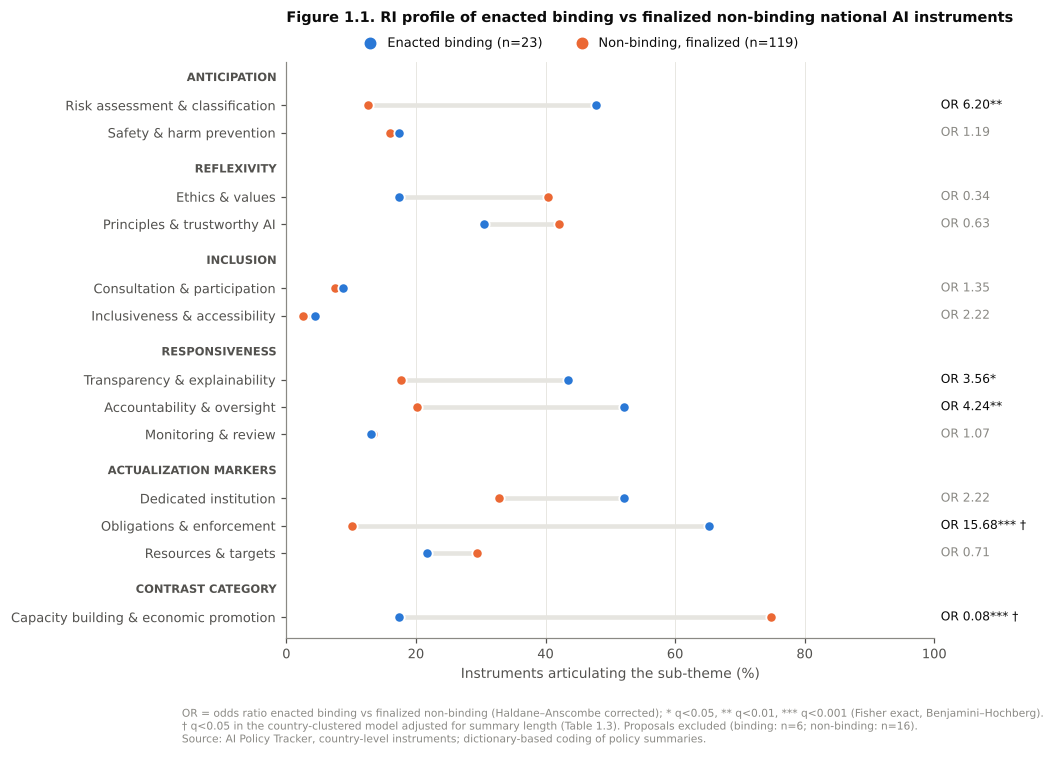

saved -> outputs/figures/Figure1_1_RQ1_RI_profile_dumbbell.pdf
saved -> outputs/tables/TableS7_RQ1_coverage_by_type_and_status.csv


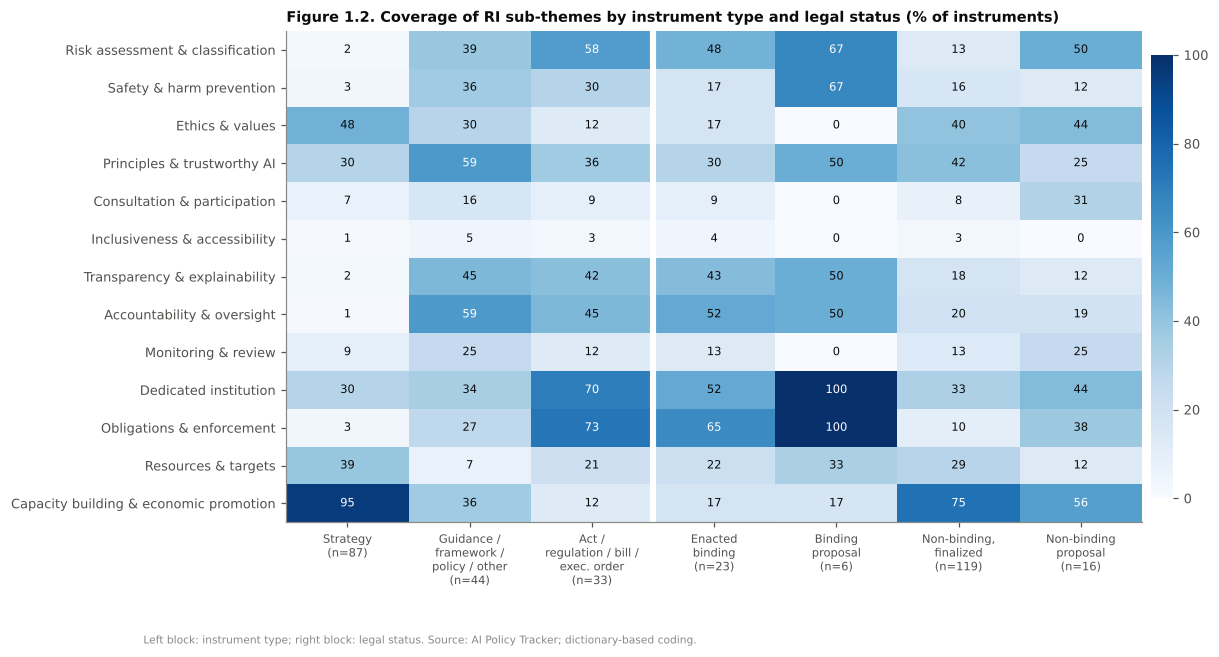

saved -> outputs/figures/Figure1_2_RQ1_coverage_heatmap.pdf


In [11]:
order = ["Anticipation", "Reflexivity", "Inclusion", "Responsiveness", "Actualization", "Contrast"]
group_title = {"Actualization": "Actualization markers", "Contrast": "Contrast category"}
ypos, headers, y = {}, [], 0
for g in order:
    headers.append((g, y)); y -= 1
    for c in CB[CB.dimension == g].code:
        ypos[c] = y; y -= 1
    y -= 0.35

fig, ax = plt.subplots(figsize=(7.6, 6.8))
d = t1.set_index("code"); adj = t13.set_index("code")
for c, yy in ypos.items():
    pb, pn = d.loc[c, "pct_Enacted binding"], d.loc[c, "pct_Non-binding"]
    ax.plot([pn, pb], [yy, yy], color=COL["grid"], lw=3, solid_capstyle="round", zorder=1)
    ax.scatter(pn, yy, s=46, color=COL["nonbinding"], edgecolor="white", linewidth=1.2, zorder=3)
    ax.scatter(pb, yy, s=46, color=COL["binding"], edgecolor="white", linewidth=1.2, zorder=3)
    q, qa = d.loc[c, "q_bh"], adj.loc[c, "q_bh"]
    mark = " †" if (pd.notna(qa) and qa < 0.05) else ""
    ax.text(1.01, yy, f"OR {d.loc[c,'odds_ratio']:.2f}{stars(q)}{mark}",
            transform=mtrans.blended_transform_factory(ax.transAxes, ax.transData),
            va="center", ha="left", fontsize=8, color=COL["ink"] if q < 0.05 else COL["muted"])
ax.set_yticks(list(ypos.values())); ax.set_yticklabels([LABEL[c] for c in ypos])
for g, yy in headers:
    ax.text(-0.015, yy, group_title.get(g, g).upper(), transform=mtrans.blended_transform_factory(ax.transAxes, ax.transData),
            ha="right", va="center", fontsize=7.5, fontweight="bold", color=COL["ink2"])
ax.set_xlim(0, 100); ax.set_ylim(y + 0.6, 0.6)
ax.set_xlabel("Instruments articulating the sub-theme (%)"); ax.grid(axis="y", visible=False)
nb, nn = int(d1.enacted_binding.sum()), int((~d1.enacted_binding).sum())
ax.scatter([], [], color=COL["binding"], s=46, label=f"Enacted binding (n={nb})")
ax.scatter([], [], color=COL["nonbinding"], s=46, label=f"Non-binding, finalized (n={nn})")
ax.legend(loc="lower center", bbox_to_anchor=(0.45, 1.0), ncol=2, handletextpad=0.3)
ax.set_title("Figure 1.1. RI profile of enacted binding vs finalized non-binding national AI instruments",
             loc="left", pad=26, fontsize=9.5)
fig.text(0.0, -0.03, "OR = odds ratio enacted binding vs finalized non-binding (Haldane–Anscombe corrected); * q<0.05, ** q<0.01, *** q<0.001 "
         "(Fisher exact, Benjamini–Hochberg).\n† q<0.05 in the country-clustered model adjusted for summary length (Table 1.3). "
         f"Proposals excluded (binding: n={int(inst.draft_binding.sum())}; non-binding: n={int(inst.nonbinding_proposal.sum())}).\n"
         "Source: AI Policy Tracker, country-level instruments; dictionary-based coding of policy summaries.",
         fontsize=7, color=COL["muted"], ha="left")
save_fig(fig, "Figure1_1_RQ1_RI_profile_dumbbell")

heat_groups = [("type3", t) for t in ["Strategy", "Guidance / framework / policy / other", "Act / regulation / bill / executive order"]]
cols, colnames = [], []
for t in ["Strategy", "Guidance / framework / policy / other", "Act / regulation / bill / executive order"]:
    s = inst[inst.type3 == t]
    cols.append(s[SUB_CODES].mean() * 100); colnames.append(f"{t}\n(n={len(s)})")
for st in STATUS3:
    s = inst[inst.legal_status3 == st]
    cols.append(s[SUB_CODES].mean() * 100); colnames.append(f"{st}\n(n={len(s)})")
H = pd.concat(cols, axis=1); H.columns = colnames
save_table(H.round(1).rename(index=LABEL).reset_index().rename(columns={"index": "sub_theme"}),
           "TableS7_RQ1_coverage_by_type_and_status", show=False)
fig, ax = plt.subplots(figsize=(10.4, 5.8))
im = ax.imshow(H.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
SHORT = {"Guidance / framework / policy / other": "Guidance /\nframework /\npolicy / other",
         "Act / regulation / bill / executive order": "Act /\nregulation / bill /\nexec. order",
         "Enacted binding": "Enacted\nbinding", "Binding proposal": "Binding\nproposal",
         "Non-binding, finalized": "Non-binding,\nfinalized", "Non-binding proposal": "Non-binding\nproposal",
         "Other binding (not in force)": "Other binding\n(not in force)"}
ax.set_xticks(range(H.shape[1]))
ax.set_xticklabels([next((c.replace(k, v) for k, v in SHORT.items() if c.startswith(k)), c) for c in H.columns], fontsize=7.5)
ax.set_yticks(range(H.shape[0])); ax.set_yticklabels([LABEL[c] for c in H.index])
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = H.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7.5, color="white" if v > 55 else COL["ink"])
ax.axvline(2.5, color="white", lw=4); ax.grid(False)
ax.set_title("Figure 1.2. Coverage of RI sub-themes by instrument type and legal status (% of instruments)", loc="left", fontsize=9.5)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.outline.set_visible(False)
fig.text(0.0, -0.08, "Left block: instrument type; right block: legal status. Source: AI Policy Tracker; dictionary-based coding.",
         fontsize=7, color=COL["muted"])
save_fig(fig, "Figure1_2_RQ1_coverage_heatmap")

## Step 9 · RQ2 – Government effectiveness, income and recorded strategy adoption
**What this cell does:**
- **Table 2.1**: adoption rates (national AI strategy recorded by the Tracker) and GE of adopters vs non-adopters, overall and within each income group (Mann–Whitney U, Cliff's δ).
- **Table 2.2**: logistic regressions of recorded strategy adoption: (M1) GE; (M2) GE + income group; (M3) GE × income group; likelihood-ratio test of M3 vs M2.
- **Table 2.3**: the same M2/M3 models and joint LR test re-estimated with **pre-period GE (2017–2022)** and **Regulatory Quality**, with **income-specific odds ratios and 95 % CIs** derived from M3 (linear combinations of the main and interaction terms).

Odds ratios are **per 1-unit increase in the WGI estimate**.
**Research question:** RQ2. **Outputs:** *Tables 2.1–2.3*.

In [12]:
def cliffs_delta(x, y):
    u = stats.mannwhitneyu(x, y).statistic
    return 2 * u / (len(x) * len(y)) - 1

def group_compare(df, flag, value="ge"):
    a, b = df[df[flag]][value].dropna(), df[~df[flag]][value].dropna()
    if len(a) < 3 or len(b) < 3:
        return [len(a), len(b), a.mean(), b.mean(), np.nan, np.nan]
    return [len(a), len(b), a.mean(), b.mean(), cliffs_delta(a, b), stats.mannwhitneyu(a, b).pvalue]

d2 = cty.dropna(subset=['ge']).copy()
rows = [["All countries", *group_compare(d2, "has_strategy")]]
for g in INC_ORDER:
    rows.append([g, *group_compare(d2[d2.income3 == g], "has_strategy")])
t2a = pd.DataFrame(rows, columns=["Group", "n_adopters", "n_non_adopters", "GE_mean_adopters",
                                  "GE_mean_non_adopters", "cliffs_delta", "p_mannwhitney"])
t2a.insert(3, "adoption_rate_pct", (100 * t2a.n_adopters / (t2a.n_adopters + t2a.n_non_adopters)).round(1))
t2a["GE_diff"] = t2a.GE_mean_adopters - t2a.GE_mean_non_adopters
save_table(t2a.round(3).assign(p_mannwhitney=t2a.p_mannwhitney.map(fmt_p)), "Table2_1_RQ2_GE_by_strategy_within_income")

REF = "C(income3, Treatment('Low & lower-middle'))"
def rq2_models(var):
    s = cty.dropna(subset=[var, "income3"]).copy()
    s["y"] = s.has_strategy.astype(int); s["income3"] = s.income3.astype(str)
    f = {"M1": f"y ~ {var}", "M2": f"y ~ {var} + {REF}", "M3": f"y ~ {var} * {REF}"}
    return s, {k: smf.glm(v, data=s, family=sm.families.Binomial()).fit() for k, v in f.items()}

def tidy(res, model, var):
    ci = res.conf_int()
    out = pd.DataFrame({"model": model, "term": res.params.index, "odds_ratio": np.exp(res.params),
                        "ci_lo": np.exp(ci[0]), "ci_hi": np.exp(ci[1]), "p": res.pvalues})
    out["term"] = (out.term.str.replace(REF, "income", regex=False).str.replace("[T.", " = ", regex=False)
                   .str.replace("]", "", regex=False).str.replace(var, f"{var.upper()} (per 1-unit WGI)", regex=False))
    return out

def lr_test(full, red):
    stat = 2 * (full.llf - red.llf); df_ = full.df_model - red.df_model
    return stat, int(df_), stats.chi2.sf(stat, df_)

def income_slopes(res, var, data):
    rows = []
    names = list(res.params.index)
    for g in INC_ORDER:
        L = np.zeros(len(names)); L[names.index(var)] = 1
        if g != "Low & lower-middle":
            L[names.index(f"{var}:{REF}[T.{g}]")] = 1
        est = L @ res.params.values; se = np.sqrt(L @ res.cov_params().values @ L)
        s = data[data.income3 == g]
        rows.append([g, len(s), int(s.y.sum()), np.exp(est), np.exp(est - 1.96 * se), np.exp(est + 1.96 * se),
                     2 * stats.norm.sf(abs(est / se))])
    return pd.DataFrame(rows, columns=["income_group", "N", "adopters", "odds_ratio", "ci_lo", "ci_hi", "p"])

GOV_MEASURES = [("ge", f"GE {WGI_YEAR} (main)"), ("ge_pre", "GE mean 2017–2022"), ("rq", f"Regulatory Quality {WGI_YEAR}")]
dm, fits = rq2_models("ge")
t2b = pd.concat([tidy(r, k, "ge") for k, r in fits.items()], ignore_index=True)
fit_rows = [{"model": k, "term": "N / AIC / McFadden R²", "fit": f"N={int(r.nobs)}; AIC={r.aic:.1f}; R²={1 - r.llf / r.llnull:.3f}"}
            for k, r in fits.items()]
lr, lr_df, lr_p = lr_test(fits["M3"], fits["M2"])
fit_rows.append({"model": "LR test M3 vs M2", "term": f"GE × income interaction (χ²={lr:.2f}, df={lr_df})", "p": lr_p, "fit": ""})
t2b = pd.concat([t2b, pd.DataFrame(fit_rows)], ignore_index=True)
t2b_show = t2b.copy()
for c in ["odds_ratio", "ci_lo", "ci_hi"]: t2b_show[c] = t2b_show[c].round(3)
t2b_show["p"] = t2b_show.p.map(fmt_p)
save_table(t2b_show.fillna(""), "Table2_2_RQ2_logit_strategy_adoption")

rob2 = []
for var, lab in GOV_MEASURES:
    s, f = rq2_models(var)
    stat, df_, p_ = lr_test(f["M3"], f["M2"])
    m2 = f["M2"]; ci = np.exp(m2.conf_int().loc[var])
    rob2.append(["M2 additive", lab, "all", int(m2.nobs), int(s.y.sum()), np.exp(m2.params[var]), ci[0], ci[1], m2.pvalues[var], np.nan, np.nan])
    for r in income_slopes(f["M3"], var, s).itertuples():
        rob2.append(["M3 income-specific", lab, r.income_group, r.N, r.adopters, r.odds_ratio, r.ci_lo, r.ci_hi, r.p, np.nan, np.nan])
    rob2.append(["LR test M3 vs M2", lab, "interaction", int(f["M3"].nobs), int(s.y.sum()), np.nan, np.nan, np.nan, p_, stat, df_])
t2c = pd.DataFrame(rob2, columns=["model", "governance_measure", "income_group", "N", "adopters",
                                  "odds_ratio_per_1unit", "ci_lo", "ci_hi", "p", "LR_chi2", "LR_df"])
save_table(t2c.round(3).assign(p=t2c.p.map(fmt_p)), "Table2_3_RQ2_income_interaction_across_governance_measures")

,Group,n_adopters,n_non_adopters,adoption_rate_pct,GE_mean_adopters,GE_mean_non_adopters,cliffs_delta,p_mannwhitney,GE_diff
0,All countries,76,119,39.0,0.623,-0.347,0.581,<0.001,0.970
1,Low & lower-middle,15,57,20.8,-0.162,-0.970,0.740,<0.001,0.808
2,Upper-middle,20,39,33.9,0.127,-0.178,0.282,0.080,0.305
3,High,41,23,64.1,1.153,0.912,0.258,0.090,0.241


saved -> outputs/tables/Table2_1_RQ2_GE_by_strategy_within_income.csv


,model,term,odds_ratio,ci_lo,ci_hi,p,fit
0,M1,Intercept,0.538,0.382,0.756,<0.001,
1,M1,GE (per 1-unit WGI),3.669,2.409,5.586,<0.001,
2,M2,Intercept,0.722,0.356,1.465,0.367,
3,M2,income = High,0.522,0.143,1.908,0.326,
4,M2,income = Upper-middle,0.727,0.291,1.815,0.495,
5,M2,GE (per 1-unit WGI),4.737,2.4,9.35,<0.001,
6,M3,Intercept,1.76,0.597,5.19,0.305,
7,M3,income = High,0.495,0.111,2.208,0.357,
8,M3,income = Upper-middle,0.298,0.088,1.011,0.052,
9,M3,GE (per 1-unit WGI),31.413,4.904,201.236,<0.001,


saved -> outputs/tables/Table2_2_RQ2_logit_strategy_adoption.csv


,model,governance_measure,income_group,N,adopters,odds_ratio_per_1unit,ci_lo,ci_hi,p,LR_chi2,LR_df
0,M2 additive,GE 2025 (main),all,195,76,4.737,2.400,9.350,<0.001,NaN,NaN
1,M3 income-specific,GE 2025 (main),Low & lower-middle,72,15,31.413,4.903,201.243,<0.001,NaN,NaN
2,M3 income-specific,GE 2025 (main),Upper-middle,59,20,5.006,1.167,21.471,0.030,NaN,NaN
3,M3 income-specific,GE 2025 (main),High,64,41,1.999,0.821,4.866,0.127,NaN,NaN
4,LR test M3 vs M2,GE 2025 (main),interaction,195,76,NaN,NaN,NaN,0.011,8.962,2.0
5,M2 additive,GE mean 2017–2022,all,195,76,3.640,1.941,6.824,<0.001,NaN,NaN
6,M3 income-specific,GE mean 2017–2022,Low & lower-middle,72,15,25.247,3.998,159.434,<0.001,NaN,NaN
7,M3 income-specific,GE mean 2017–2022,Upper-middle,59,20,4.495,1.107,18.251,0.036,NaN,NaN
8,M3 income-specific,GE mean 2017–2022,High,64,41,1.724,0.777,3.825,0.180,NaN,NaN
9,LR test M3 vs M2,GE mean 2017–2022,interaction,195,76,NaN,NaN,NaN,0.010,9.250,2.0


saved -> outputs/tables/Table2_3_RQ2_income_interaction_across_governance_measures.csv


### Figure 2.1 · Predicted adoption and GE distributions by income group; Figure 2.2 · adoption by region and GE tercile
**What this cell does:** Figure 2.1 (a) plots the predicted probability of a recorded national AI strategy across the observed GE range per income group (model M3, 95 % CI) and (b) each country's GE by adoption status within income groups. Figure 2.2 is a heat map of recorded strategy adoption (%) by world region and GE tercile, with cell sizes.
**Research question:** RQ2. **Outputs:** *Figure 2.1, Figure 2.2*.

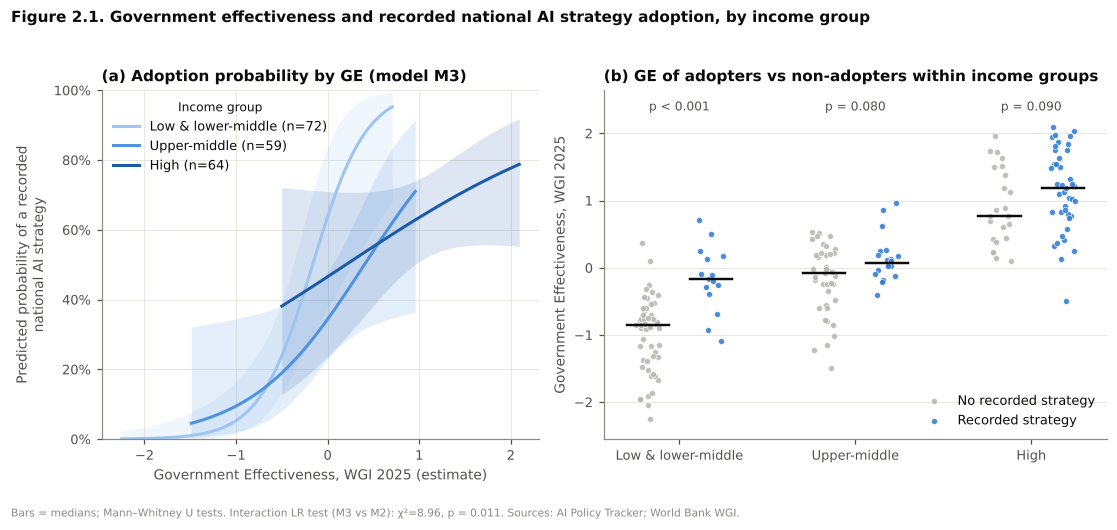

saved -> outputs/figures/Figure2_1_RQ2_GE_income_strategy_adoption.pdf
saved -> outputs/tables/TableS8_RQ2_adoption_by_region_GE_tercile.csv


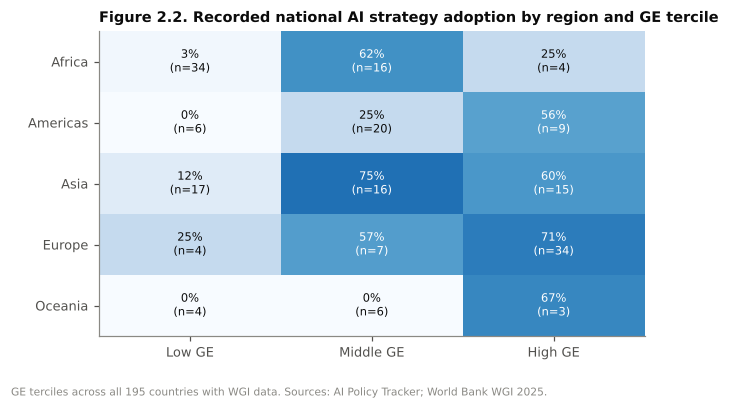

saved -> outputs/figures/Figure2_2_RQ2_adoption_region_GE_tercile.pdf


In [13]:
fig, (axa, axb) = plt.subplots(1, 2, figsize=(10.2, 4.3), gridspec_kw={"width_ratios": [1, 1.15]})
m3 = fits["M3"]
for g, col in zip(INC_ORDER, INCOME_SEQ):
    s = dm[dm.income3 == g]
    grid = pd.DataFrame({"ge": np.linspace(s['ge'].min(), s['ge'].max(), 80), "income3": g})
    pr = m3.get_prediction(grid).summary_frame()
    axa.fill_between(grid['ge'], pr.mean_ci_lower, pr.mean_ci_upper, color=col, alpha=0.15, lw=0)
    axa.plot(grid['ge'], pr["mean"], color=col, lw=2, label=f"{g} (n={len(s)})")
axa.set_ylim(0, 1); axa.set_xlabel(f"Government Effectiveness, WGI {WGI_YEAR} (estimate)")
axa.set_ylabel("Predicted probability of a recorded\nnational AI strategy")
axa.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
axa.legend(loc="upper left", title="Income group", title_fontsize=8)
axa.set_title("(a) Adoption probability by GE (model M3)", loc="left")
for i, g in enumerate(INC_ORDER):
    s = d2[d2.income3 == g]
    for j, (flag, col, lab) in enumerate([(False, COL["none"], "No recorded strategy"), (True, COL["binding"], "Recorded strategy")]):
        v = s[s.has_strategy == flag]['ge']; off = -0.18 if j == 0 else 0.18
        axb.scatter(i + off + rng.uniform(-0.07, 0.07, len(v)), v, s=16, color=col, alpha=0.85, edgecolor="white",
                    linewidth=0.5, zorder=3, label=lab if i == 0 else None)
        axb.plot([i + off - 0.12, i + off + 0.12], [v.median()] * 2, color=COL["ink"], lw=1.6, zorder=4)
    p = t2a.set_index("Group").loc[g, "p_mannwhitney"]
    axb.text(i, d2['ge'].max() + 0.25, f"{pstr(p)}", ha="center", fontsize=8, color=COL["ink2"])
axb.set_xticks(range(3)); axb.set_xticklabels(INC_ORDER)
axb.set_ylabel(f"Government Effectiveness, WGI {WGI_YEAR}")
axb.set_ylim(d2['ge'].min() - 0.3, d2['ge'].max() + 0.55); axb.grid(axis="x", visible=False)
axb.legend(loc="lower right")
axb.set_title("(b) GE of adopters vs non-adopters within income groups", loc="left")
fig.suptitle("Figure 2.1. Government effectiveness and recorded national AI strategy adoption, by income group",
             x=0.01, ha="left", fontsize=10, fontweight="bold", y=1.03)
fig.text(0.01, -0.04, f"Bars = medians; Mann–Whitney U tests. Interaction LR test (M3 vs M2): χ²={lr:.2f}, {pstr(lr_p)}. "
         "Sources: AI Policy Tracker; World Bank WGI.", fontsize=7, color=COL["muted"])
fig.tight_layout()
save_fig(fig, "Figure2_1_RQ2_GE_income_strategy_adoption")

d22 = d2.dropna(subset=["region"]).copy()
d22["ge_tercile"] = pd.qcut(d22["ge"], 3, labels=["Low GE", "Middle GE", "High GE"])
ad = d22.pivot_table(index="region", columns="ge_tercile", values="has_strategy", aggfunc="mean", observed=False) * 100
nn_ = d22.pivot_table(index="region", columns="ge_tercile", values="has_strategy", aggfunc="size", observed=False)
save_table(ad.round(1).astype(object).where(nn_ > 0, "").reset_index(), "TableS8_RQ2_adoption_by_region_GE_tercile", show=False)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
im = ax.imshow(ad.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
for i in range(ad.shape[0]):
    for j in range(ad.shape[1]):
        n = nn_.values[i, j]
        if n > 0:
            v = ad.values[i, j]
            ax.text(j, i, f"{v:.0f}%\n(n={int(n)})", ha="center", va="center", fontsize=7.5,
                    color="white" if v > 55 else COL["ink"])
        else:
            ax.text(j, i, "–", ha="center", va="center", fontsize=8, color=COL["muted"])
ax.set_xticks(range(3)); ax.set_xticklabels(ad.columns)
ax.set_yticks(range(len(ad.index))); ax.set_yticklabels(ad.index); ax.grid(False)
ax.set_title("Figure 2.2. Recorded national AI strategy adoption by region and GE tercile", loc="left", fontsize=9.5)
fig.text(0.0, -0.04, f"GE terciles across all {len(d22)} countries with WGI data. Sources: AI Policy Tracker; World Bank WGI {WGI_YEAR}.",
         fontsize=7, color=COL["muted"])
save_fig(fig, "Figure2_2_RQ2_adoption_region_GE_tercile")

## Step 10 · RQ3 – Recorded policies and enacted national binding measures
**Question as analysed.** Among countries with a recorded AI policy, is government effectiveness associated with having an enacted national binding measure? (The proposal's wording – whether strategic commitments are *actualized* into binding instruments or *decoupled* – would require linking individual strategies to subsequent laws; Table 3.4 shows why the cross-sectional data cannot do this, so the decoupling interpretation is not claimed.)
**What this cell does (cross-sectional associations, not transitions):**
- **Table 3.1** – GE across the three policy stages: Kruskal–Wallis omnibus test and Holm-adjusted pairwise Mann–Whitney tests.
- **Table 3.2** – two-stage **Firth penalised logistic regression**. Stage 1: having any recorded AI policy (all countries); Stage 2: among countries with a recorded policy, having an **enacted national binding measure** (GE + EU membership). Each model reports the rank of the design matrix, convergence, iterations, penalised-LR p-values and **profile penalised-likelihood 95 % CIs** (recommended for sparse outcomes; Wald CIs shown for comparison).
- **Table 3.3** – among countries with an adopted strategy, Spearman correlation of GE with the implementation concreteness of the strategy summary.
- **Table 3.4** – recorded strategy × enacted national binding measure, and the chronology of first strategy vs first enacted binding measure among countries with both. The analysis therefore measures *co-occurrence* of recorded instruments; it does not establish that a strategy was translated into a law.

**Research question:** RQ3. **Outputs:** *Tables 3.1–3.4*.

In [14]:
def firth_logit(y, X, names, max_iter=500, tol=1e-8, ci_level=0.95):
    # Firth (1993) penalised-likelihood logistic regression.
    # p-values: penalised likelihood-ratio tests (Heinze & Schemper 2002; R logistf convention: the restricted
    # model fixes beta_k = 0 and keeps the Jeffreys penalty of the full design).
    # CIs: profile penalised likelihood (Heinze & Schemper 2002) and Wald, for comparison.
    y = np.asarray(y, float); X = np.asarray(X, float); k_all = X.shape[1]
    rank = np.linalg.matrix_rank(X)
    assert rank == k_all, f"design matrix not of full rank ({rank} < {k_all})"
    def pll(b):
        p = np.clip(expit(X @ b), 1e-12, 1 - 1e-12); W = p * (1 - p)
        return np.sum(y * np.log(p) + (1 - y) * np.log(1 - p)) + 0.5 * np.linalg.slogdet(X.T @ (X * W[:, None]))[1]
    def fit(free, b0):
        b = b0.copy(); conv = False
        for it in range(1, max_iter + 1):
            p = expit(X @ b); W = p * (1 - p)
            XtWX = X.T @ (X * W[:, None]); inv = np.linalg.inv(XtWX)
            A = X * np.sqrt(W)[:, None]; h = np.einsum("ij,jk,ik->i", A, inv, A)
            U = X.T @ (y - p + h * (0.5 - p))
            step = np.zeros_like(b); step[free] = np.linalg.solve(XtWX[np.ix_(free, free)], U[free])
            ll_old, t = pll(b), 1.0
            while pll(b + t * step) < ll_old - 1e-12 and t > 1e-6:
                t /= 2
            b = b + t * step
            if np.max(np.abs(t * step)) < tol:
                conv = True; break
        return b, pll(b), conv, it
    allk = np.arange(k_all)
    b, ll_full, conv, iters = fit(allk, np.zeros(k_all))
    p_ = expit(X @ b); W = p_ * (1 - p_)
    se = np.sqrt(np.diag(np.linalg.inv(X.T @ (X * W[:, None]))))
    crit = stats.chi2.ppf(ci_level, 1) / 2
    rows = []
    for k, nm in enumerate(names):
        others = allk[allk != k]
        def prof(v):
            b0 = b.copy(); b0[k] = v
            return fit(others, b0)[1] - (ll_full - crit)
        lo = hi = np.nan
        try:
            step = 2 * se[k]
            a = b[k] - step
            while prof(a) > 0 and a > b[k] - 60 * se[k]: a -= step
            lo = optimize.brentq(prof, a, b[k], xtol=1e-7)
            a = b[k] + step
            while prof(a) > 0 and a < b[k] + 60 * se[k]: a += step
            hi = optimize.brentq(prof, b[k], a, xtol=1e-7)
        except Exception:
            pass
        if k == 0:
            p_lr = np.nan
        else:
            b0 = b.copy(); b0[k] = 0.0
            ll_red = fit(others, b0)[1]
            p_lr = stats.chi2.sf(max(0.0, 2 * (ll_full - ll_red)), 1)
        rows.append([nm, np.exp(b[k]), np.exp(lo), np.exp(hi), np.exp(b[k] - 1.96 * se[k]), np.exp(b[k] + 1.96 * se[k]), p_lr])
    out = pd.DataFrame(rows, columns=["term", "odds_ratio", "profile_ci_lo", "profile_ci_hi", "wald_ci_lo", "wald_ci_hi", "p_penalised_LR"])
    out["converged"] = conv; out["iterations"] = iters; out["rank"] = f"{rank}/{k_all}"
    return out

def run_firth(df, outcome, predictors, label):
    s = df.dropna(subset=[outcome] + predictors)
    X = np.column_stack([np.ones(len(s))] + [s[p].astype(float) for p in predictors])
    res = firth_logit(s[outcome].astype(int), X, ["Intercept"] + predictors)
    res.insert(0, "model", label); res.insert(1, "model_terms", " + ".join(predictors))
    res["N"] = len(s); res["events"] = int(s[outcome].sum())
    return res

d3 = cty.dropna(subset=['ge']).copy()
d3["eu"] = d3.eu_member.astype(int)

g_ = [d3[d3.policy_stage == s]['ge'] for s in STAGES]
kw = stats.kruskal(*g_)
t3a = pd.DataFrame({"policy_stage": STAGES, "n": [len(x) for x in g_], "GE_mean": [x.mean() for x in g_],
                    "GE_median": [x.median() for x in g_]})
pair = [(STAGES[0], STAGES[1]), (STAGES[1], STAGES[2]), (STAGES[0], STAGES[2])]
pair_rows = []
for a, b_ in pair:
    xa, xb = d3[d3.policy_stage == b_]['ge'], d3[d3.policy_stage == a]['ge']
    pair_rows.append([f"{b_} vs {a}", len(xa), len(xb), xa.mean() - xb.mean(), cliffs_delta(xa, xb),
                      stats.mannwhitneyu(xa, xb).statistic, stats.mannwhitneyu(xa, xb).pvalue])
t3a_pairs = pd.DataFrame(pair_rows, columns=["comparison", "n_1", "n_2", "GE_diff", "cliffs_delta", "statistic", "p"])
t3a_pairs["p_holm"] = multipletests(t3a_pairs.p, method="holm")[1]
t3a_pairs.insert(0, "test", "Mann–Whitney U (pairwise)")
omni = pd.DataFrame([["Kruskal–Wallis H (omnibus)", "all three stages", int(sum(len(x) for x in g_)), np.nan,
                      np.nan, np.nan, kw.statistic, kw.pvalue, np.nan]], columns=t3a_pairs.columns)
t31_tests = pd.concat([omni, t3a_pairs], ignore_index=True)
save_table(t3a.round(3), "Table3_1a_RQ3_GE_by_policy_stage")
save_table(t31_tests.round(3).assign(p=t31_tests.p.map(fmt_p), p_holm=t31_tests.p_holm.map(fmt_p)),
           "Table3_1b_RQ3_omnibus_and_pairwise_tests")

adopters = d3[d3.has_any_policy]
t3b = pd.concat([
    run_firth(d3, "has_any_policy", ['ge'], "Stage 1: any recorded AI policy ~ GE (all countries)"),
    run_firth(d3, "has_strategy", ['ge'], "Stage 1b: recorded strategy ~ GE (all countries)"),
    run_firth(adopters, "binding_national", ['ge'], "Stage 2: enacted national binding measure ~ GE (countries with policy)"),
    run_firth(adopters, "binding_national", ["ge", "eu"], "Stage 2 (main): enacted national binding measure ~ GE + EU member"),
], ignore_index=True)
assert t3b.converged.all(), "a Firth model did not converge"
t3b_show = t3b.copy()
for c in ["odds_ratio", "profile_ci_lo", "profile_ci_hi", "wald_ci_lo", "wald_ci_hi"]: t3b_show[c] = t3b_show[c].round(3)
t3b_show["p_penalised_LR"] = t3b_show.p_penalised_LR.map(fmt_p)
save_table(t3b_show, "Table3_2_RQ3_two_stage_firth_logit")

strat = inst[inst.adopted_strategy].groupby("country").agg(
    impl_concreteness=("impl_concreteness", "max"), n_ri_dims=("n_ri_dims", "max"))
d3c = d3.merge(strat, left_on="country", right_index=True)
rows = []
for v, lab in [("impl_concreteness", "Implementation concreteness (0–3)"), ("n_ri_dims", "Number of RI dimensions (0–4)")]:
    r = stats.spearmanr(d3c['ge'], d3c[v])
    rows.append([lab, len(d3c), d3c[v].mean(), r.statistic, r.pvalue])
t3c = pd.DataFrame(rows, columns=["strategy_content_measure", "N_countries", "mean", "spearman_rho_with_GE", "p"])
save_table(t3c.round(3).assign(p=t3c.p.map(fmt_p)), "Table3_3_RQ3_strategy_concreteness_vs_GE")

xt = pd.crosstab(cty.has_strategy.map({True: "Recorded adopted strategy", False: "No recorded adopted strategy"}),
                 cty.binding_national.map({True: "Enacted national binding measure", False: "No enacted national binding measure"}),
                 margins=True, margins_name="Total")
both = cty[cty.has_strategy & cty.binding_national].copy()
def chrono(r):
    if pd.isna(r.first_strategy_year) or pd.isna(r.first_binding_year): return "date missing"
    if r.first_binding_year > r.first_strategy_year: return "binding measure later than strategy"
    if r.first_binding_year == r.first_strategy_year: return "same year"
    return "binding measure earlier than strategy"
both["chronology"] = both.apply(chrono, axis=1)
chron = both.chronology.value_counts().rename_axis("chronology (countries with both)").reset_index(name="countries")
save_table(xt.reset_index().rename(columns={"has_strategy": ""}), "Table3_4a_RQ3_strategy_x_enacted_binding")
save_table(chron, "Table3_4b_RQ3_chronology_strategy_vs_binding")
save_table(cty[cty.binding_national][["country_name", "has_strategy", "first_strategy_year", "first_binding_year", "eu_member"]]
           .sort_values("country_name"), "TableS9_RQ3_countries_with_enacted_binding", show=False)

,policy_stage,n,GE_mean,GE_median
0,No recorded instrument,90,-0.517,-0.628
1,"Recorded policy, no enacted national binding measure",88,0.502,0.312
2,Enacted national binding measure,17,0.502,0.322


saved -> outputs/tables/Table3_1a_RQ3_GE_by_policy_stage.csv


,test,comparison,n_1,n_2,GE_diff,cliffs_delta,statistic,p,p_holm
0,Kruskal–Wallis H (omnibus),all three stages,195,NaN,NaN,NaN,52.043,<0.001,n/a
1,Mann–Whitney U (pairwise),"Recorded policy, no enacted national binding measure vs No recorded instrument",88,90.0,1.019,0.593,6307.000,<0.001,<0.001
2,Mann–Whitney U (pairwise),"Enacted national binding measure vs Recorded policy, no enacted national bin...",17,88.0,-0.000,0.024,766.000,0.879,0.879
3,Mann–Whitney U (pairwise),Enacted national binding measure vs No recorded instrument,17,90.0,1.019,0.635,1251.000,<0.001,<0.001


saved -> outputs/tables/Table3_1b_RQ3_omnibus_and_pairwise_tests.csv


,model,model_terms,term,odds_ratio,profile_ci_lo,profile_ci_hi,wald_ci_lo,wald_ci_hi,p_penalised_LR,converged,iterations,rank,N,events
0,Stage 1: any recorded AI policy ~ GE (all countries),ge,Intercept,1.204,0.866,1.683,0.864,1.678,n/a,True,6,2/2,195,105
1,Stage 1: any recorded AI policy ~ GE (all countries),ge,ge,4.225,2.772,6.845,2.695,6.625,<0.001,True,6,2/2,195,105
2,Stage 1b: recorded strategy ~ GE (all countries),ge,Intercept,0.542,0.383,0.755,0.386,0.761,n/a,True,6,2/2,195,76
3,Stage 1b: recorded strategy ~ GE (all countries),ge,ge,3.572,2.414,5.554,2.357,5.412,<0.001,True,6,2/2,195,76
4,Stage 2: enacted national binding measure ~ GE (countries with policy),ge,Intercept,0.202,0.105,0.353,0.110,0.368,n/a,True,7,2/2,105,17
5,Stage 2: enacted national binding measure ~ GE (countries with policy),ge,ge,1.007,0.528,1.884,0.535,1.896,0.983,True,7,2/2,105,17
6,Stage 2 (main): enacted national binding measure ~ GE + EU member,ge + eu,Intercept,0.219,0.113,0.388,0.118,0.405,n/a,True,8,3/3,105,17
7,Stage 2 (main): enacted national binding measure ~ GE + EU member,ge + eu,ge,1.174,0.581,2.295,0.592,2.327,0.644,True,8,3/3,105,17
8,Stage 2 (main): enacted national binding measure ~ GE + EU member,ge + eu,eu,0.549,0.122,2.037,0.137,2.207,0.380,True,8,3/3,105,17


saved -> outputs/tables/Table3_2_RQ3_two_stage_firth_logit.csv


... (2 outputs left out)

binding_national,,Enacted national binding measure,No enacted national binding measure,Total
0,No recorded adopted strategy,6,115,121
1,Recorded adopted strategy,11,65,76
2,Total,17,180,197


saved -> outputs/tables/Table3_4a_RQ3_strategy_x_enacted_binding.csv


,chronology (countries with both),countries
0,binding measure later than strategy,7
1,binding measure earlier than strategy,2
2,same year,2


saved -> outputs/tables/Table3_4b_RQ3_chronology_strategy_vs_binding.csv
saved -> outputs/tables/TableS9_RQ3_countries_with_enacted_binding.csv


### Figure 3.1 · GE across policy stages and strategy concreteness; Figure 3.2 · Stage 2 odds ratios across specifications
**What this cell does:** Figure 3.1 (a) shows each country's GE in the three policy stages with medians and Holm-adjusted tests, and (b) GE against the implementation concreteness of recorded strategies. Figure 3.2 is a forest plot of the Stage 2 GE odds ratio (profile CIs) across the specifications in Table S3, making the uncertainty of the sparse Stage 2 estimate visible.
**Research question:** RQ3. **Outputs:** *Figure 3.1, Figure 3.2*.

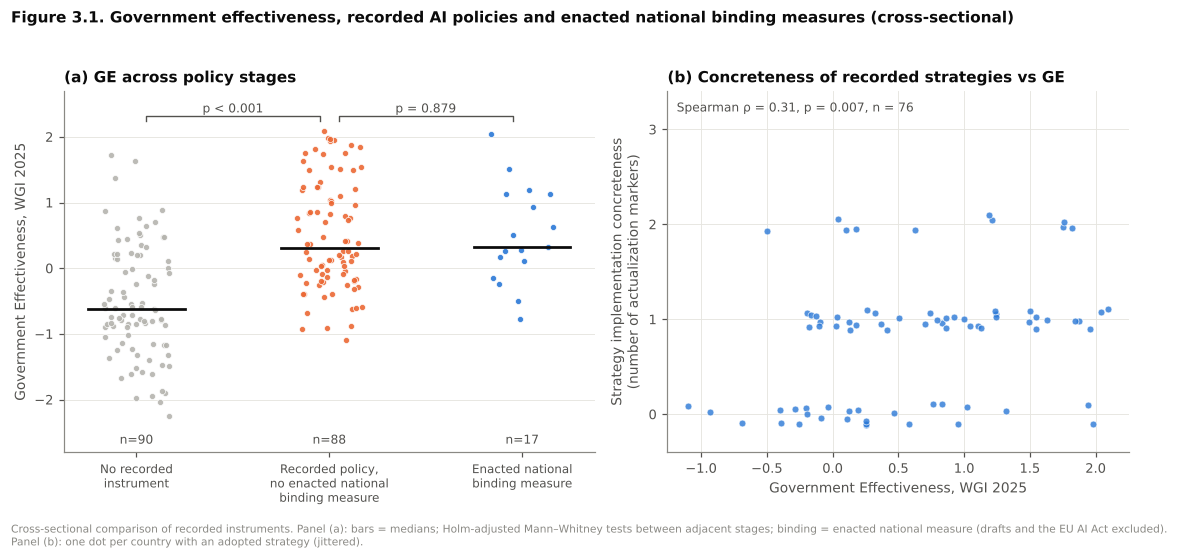

saved -> outputs/figures/Figure3_1_RQ3_policy_stages_and_concreteness.pdf


In [15]:
fig, (axa, axb) = plt.subplots(1, 2, figsize=(10.4, 4.5), gridspec_kw={"width_ratios": [1.15, 1]})
stage_col = dict(zip(STAGES, [COL["none"], COL["nonbinding"], COL["binding"]]))
for i, s in enumerate(STAGES):
    v = d3[d3.policy_stage == s]['ge']
    axa.scatter(i + rng.uniform(-0.17, 0.17, len(v)), v, s=16, color=stage_col[s], edgecolor="white",
                linewidth=0.5, alpha=0.9, zorder=3)
    axa.plot([i - 0.25, i + 0.25], [v.median()] * 2, color=COL["ink"], lw=1.8, zorder=4)
    axa.text(i, d3['ge'].min() - 0.42, f"n={len(v)}", ha="center", fontsize=8, color=COL["ink2"])
top = d3['ge'].max()
for k, (a, b_) in enumerate(pair[:2]):
    i0, i1 = STAGES.index(a), STAGES.index(b_); yb = top + 0.22
    axa.plot([i0 + 0.05, i0 + 0.05, i1 - 0.05, i1 - 0.05], [yb - 0.07, yb, yb, yb - 0.07], color=COL["ink2"], lw=0.9)
    axa.text((i0 + i1) / 2, yb + 0.06, pstr(t3a_pairs.loc[k, "p_holm"]), ha="center", fontsize=8, color=COL["ink2"])
axa.set_xticks(range(3)); axa.set_xticklabels([STAGE_SHORT[s] for s in STAGES], fontsize=7.8)
axa.set_ylim(d3['ge'].min() - 0.55, top + 0.6); axa.grid(axis="x", visible=False)
axa.set_ylabel(f"Government Effectiveness, WGI {WGI_YEAR}")
axa.set_title("(a) GE across policy stages", loc="left")
xj = d3c.impl_concreteness + rng.uniform(-0.12, 0.12, len(d3c))
axb.scatter(d3c['ge'], xj, s=20, color=COL["binding"], alpha=0.8, edgecolor="white", linewidth=0.5, zorder=3)
r = t3c.iloc[0]
axb.set_yticks([0, 1, 2, 3]); axb.set_ylim(-0.4, 3.4)
axb.set_xlabel(f"Government Effectiveness, WGI {WGI_YEAR}")
axb.set_ylabel("Strategy implementation concreteness\n(number of actualization markers)")
axb.text(0.02, 0.97, f"Spearman ρ = {r.spearman_rho_with_GE:.2f}, {pstr(r.p)}, n = {int(r.N_countries)}",
         transform=axb.transAxes, va="top", fontsize=8, color=COL["ink2"])
axb.set_title("(b) Concreteness of recorded strategies vs GE", loc="left")
fig.suptitle("Figure 3.1. Government effectiveness, recorded AI policies and enacted national binding measures (cross-sectional)",
             x=0.01, ha="left", fontsize=10, fontweight="bold", y=1.03)
fig.text(0.01, -0.05, "Cross-sectional comparison of recorded instruments. Panel (a): bars = medians; Holm-adjusted Mann–Whitney tests "
         "between adjacent stages; binding = enacted national measure (drafts and the EU AI Act excluded).\n"
         "Panel (b): one dot per country with an adopted strategy (jittered).", fontsize=7, color=COL["muted"])
fig.tight_layout()
save_fig(fig, "Figure3_1_RQ3_policy_stages_and_concreteness")

## Step 11 · RQ4 – Pre-generative-AI vs generative-AI period
**What this cell does:**
- **Table 4.3** reports undated instruments by instrument type and legal status, and the source of every reference date.
- **Table 4.1** (main) compares instruments with reference years **2017–2022** and **2023–2025** (complete years only) on legal status (enacted binding, draft binding, Tracker flag), instrument type and RI profile: Fisher exact tests, BH correction; changes in the binding share are interpreted descriptively.
- **Table 4.4** re-estimates the period contrast (i) with country-clustered logistic regression adjusted for summary length, (ii) on finalized instruments only (proposals excluded) and (iii) with partial 2026 included.

All period contrasts describe differences in the **mix of recorded instruments**, not changes within instruments.
- **Table 4.2** gives the instrument-type composition by period (n and %).

**Research question:** RQ4. **Outputs:** *Tables 4.1–4.4*.

In [16]:
LAST_FULL_YEAR = 2025
miss = (inst.assign(dated=np.where(inst.year.notna(), "dated", "undated"))
        .pivot_table(index=["type3", "legal_status3"], columns="dated", values="slug", aggfunc="count", fill_value=0, observed=True))
miss["undated_pct"] = (100 * miss.get("undated", 0) / miss.sum(axis=1)).round(1)
save_table(miss.reset_index(), "Table4_3a_RQ4_undated_by_type_and_status")
save_table(inst.date_source.value_counts().rename_axis("reference_date_source").reset_index(name="instruments"),
           "Table4_3b_RQ4_reference_date_source")

def period_frame(last_year):
    d = inst.dropna(subset=["year"]).copy()
    d = d[(d.year >= 2017) & (d.year <= last_year)]
    d["period"] = np.where(d.year >= 2023, "2023+", "2017–2022")
    d["post"] = (d.period == "2023+").astype(int)
    d["enacted"] = d.enacted_binding.astype(int); d["proposal"] = d.proposal_stage.astype(int)
    d["binding_flag"] = d.is_binding.astype(int)
    d["type_strategy"] = (d.type3 == "Strategy").astype(int)
    d["type_hard_law"] = (d.type3 == "Act / regulation / bill / executive order").astype(int)
    d["type_soft_other"] = (d.type3 == "Guidance / framework / policy / other").astype(int)
    return d

lab4 = {**LABEL, "enacted": "Enacted binding instrument", "proposal": "Proposal (proposed / under consultation)",
        "binding_flag": "Binding (Tracker flag, incl. drafts)", "type_strategy": "Type: strategy",
        "type_hard_law": "Type: act / regulation / bill / exec. order",
        "type_soft_other": "Type: guidance / framework / policy / other"}
RQ4_CODES = ["enacted", "proposal", "binding_flag", "type_strategy", "type_hard_law", "type_soft_other"] + DIM_CODES + ["cap_capacity"]
d4 = period_frame(LAST_FULL_YEAR)
print(f"Instruments 2017–{LAST_FULL_YEAR}: {len(d4)} of {len(inst)} | undated: {inst.year.isna().sum()} | "
      f"pre-2017: {(inst.year < 2017).sum()} | after {LAST_FULL_YEAR} (partial year): {(inst.year > LAST_FULL_YEAR).sum()}")
t4 = compare_binary(d4, "period", RQ4_CODES, "2023+", "2017–2022", labels=lab4)
save_table(show_compare(t4, "2023+", "2017–2022"), f"Table4_1_RQ4_period_comparison_2017_{LAST_FULL_YEAR}")

comp = pd.crosstab(d4.type3, d4.period, margins=True, margins_name="Total")
comp_pct = (100 * comp / comp.loc["Total"]).round(1)
t42 = pd.concat([comp.add_prefix("n_"), comp_pct.add_prefix("pct_")], axis=1).reset_index()
save_table(t42, "Table4_2_RQ4_instrument_type_composition")

d4all = period_frame(inst.year.max())
t44a = clustered_logit(d4, RQ4_CODES, "post", lab4).assign(specification=f"2017–{LAST_FULL_YEAR}, country-clustered, length-adjusted")
t44b = compare_binary(d4all, "period", RQ4_CODES, "2023+", "2017–2022", labels=lab4)
t44b = t44b.rename(columns={"or_ci_lo": "ci_lo", "or_ci_hi": "ci_hi", "p_fisher": "p_cluster"})[
    ["code", "label", "odds_ratio", "ci_lo", "ci_hi", "p_cluster", "q_bh"]].rename(columns={"odds_ratio": "adj_odds_ratio"})
t44b = t44b.assign(note="unadjusted Fisher", specification=f"2017–{int(inst.year.max())} incl. partial year")
d4fin = d4[~d4.proposal_stage]
t44c = compare_binary(d4fin, "period", [c for c in RQ4_CODES if c != "proposal"], "2023+", "2017–2022", labels=lab4)
t44c = t44c.rename(columns={"or_ci_lo": "ci_lo", "or_ci_hi": "ci_hi", "p_fisher": "p_cluster", "odds_ratio": "adj_odds_ratio"})[
    ["code", "label", "adj_odds_ratio", "ci_lo", "ci_hi", "p_cluster", "q_bh"]].assign(
    note="unadjusted Fisher", specification=f"2017–{LAST_FULL_YEAR}, finalized instruments only (proposals excluded)")
t44 = pd.concat([t44a, t44c, t44b], ignore_index=True)[["specification", "code", "label", "adj_odds_ratio", "ci_lo", "ci_hi",
                                                  "p_cluster", "q_bh", "note"]].rename(columns={"adj_odds_ratio": "odds_ratio", "p_cluster": "p"})
save_table(t44.round(3).assign(p=t44.p.map(fmt_p), q_bh=t44.q_bh.map(fmt_p)), "Table4_4_RQ4_sensitivity")

dated,type3,legal_status3,dated,undated,undated_pct
0,Act / regulation / bill / executive order,Enacted binding,22,0,0.0
1,Act / regulation / bill / executive order,Binding proposal,1,5,83.3
2,Act / regulation / bill / executive order,"Non-binding, finalized",1,0,0.0
3,Act / regulation / bill / executive order,Non-binding proposal,4,0,0.0
4,Guidance / framework / policy / other,Enacted binding,1,0,0.0
5,Guidance / framework / policy / other,"Non-binding, finalized",32,7,17.9
6,Guidance / framework / policy / other,Non-binding proposal,3,1,25.0
7,Strategy,"Non-binding, finalized",64,15,19.0
8,Strategy,Non-binding proposal,3,5,62.5


saved -> outputs/tables/Table4_3a_RQ4_undated_by_type_and_status.csv


,reference_date_source,instruments
0,adopted_on,127
1,missing,33
2,published_on,4


saved -> outputs/tables/Table4_3b_RQ4_reference_date_source.csv
Instruments 2017–2025: 123 of 164 | undated: 33 | pre-2017: 0 | after 2025 (partial year): 8


,code,label,n_2023+,N_2023+,pct_2023+,n_2017–2022,N_2017–2022,pct_2017–2022,diff_pp,odds_ratio,or_ci_lo,or_ci_hi,p_fisher,q_bh
0,enacted,Enacted binding instrument,19,80,23.8,4,43,9.3,14.4,2.78,0.93,8.36,0.056,0.084
1,proposal,Proposal (proposed / under consultation),8,80,10.0,0,43,0.0,10.0,10.20,0.57,181.14,0.049,0.084
2,binding_flag,"Binding (Tracker flag, incl. drafts)",20,80,25.0,4,43,9.3,15.7,2.97,0.99,8.90,0.055,0.084
3,type_strategy,Type: strategy,32,80,40.0,32,43,74.4,-34.4,0.24,0.11,0.53,<0.001,0.004
4,type_hard_law,Type: act / regulation / bill / exec. order,22,80,27.5,5,43,11.6,15.9,2.69,0.97,7.45,0.066,0.088
5,type_soft_other,Type: guidance / framework / policy / other,26,80,32.5,6,43,14.0,18.5,2.81,1.08,7.28,0.031,0.075
6,dim_anticipation,Anticipation,33,80,41.2,7,43,16.3,25.0,3.43,1.39,8.46,0.005,0.015
7,dim_reflexivity,Reflexivity,43,80,53.8,29,43,67.4,-13.7,0.57,0.27,1.23,0.180,0.196
8,dim_inclusion,Inclusion,11,80,13.8,5,43,11.6,2.1,1.16,0.39,3.44,1.000,1.000
9,dim_responsiveness,Responsiveness,43,80,53.8,11,43,25.6,28.2,3.28,1.47,7.31,0.004,0.015


saved -> outputs/tables/Table4_1_RQ4_period_comparison_2017_2025.csv


period,type3,n_2017–2022,n_2023+,n_Total,pct_2017–2022,pct_2023+,pct_Total
0,Act / regulation / bill / executive order,5,22,27,11.6,27.5,22.0
1,Guidance / framework / policy / other,6,26,32,14.0,32.5,26.0
2,Strategy,32,32,64,74.4,40.0,52.0
3,Total,43,80,123,100.0,100.0,100.0


saved -> outputs/tables/Table4_2_RQ4_instrument_type_composition.csv


,specification,code,label,odds_ratio,ci_lo,ci_hi,p,q_bh,note
0,"2017–2025, country-clustered, length-adjusted",enacted,Enacted binding instrument,2.143,0.608,7.555,0.236,0.324,ok
1,"2017–2025, country-clustered, length-adjusted",proposal,Proposal (proposed / under consultation),NaN,NaN,NaN,n/a,n/a,not estimable (zero cell)
2,"2017–2025, country-clustered, length-adjusted",binding_flag,"Binding (Tracker flag, incl. drafts)",2.331,0.674,8.060,0.181,0.324,ok
3,"2017–2025, country-clustered, length-adjusted",type_strategy,Type: strategy,0.286,0.123,0.663,0.004,0.039,ok
4,"2017–2025, country-clustered, length-adjusted",type_hard_law,Type: act / regulation / bill / exec. order,2.002,0.669,5.987,0.214,0.324,ok
5,"2017–2025, country-clustered, length-adjusted",type_soft_other,Type: guidance / framework / policy / other,2.538,0.893,7.210,0.080,0.177,ok
6,"2017–2025, country-clustered, length-adjusted",dim_anticipation,Anticipation,2.663,1.000,7.092,0.050,0.177,ok
7,"2017–2025, country-clustered, length-adjusted",dim_reflexivity,Reflexivity,0.664,0.303,1.455,0.307,0.337,ok
8,"2017–2025, country-clustered, length-adjusted",dim_inclusion,Inclusion,0.879,0.332,2.327,0.795,0.795,ok
9,"2017–2025, country-clustered, length-adjusted",dim_responsiveness,Responsiveness,2.549,0.922,7.049,0.071,0.177,ok


saved -> outputs/tables/Table4_4_RQ4_sensitivity.csv


### Figure 4.1 · Recorded instruments by reference year; Figure 4.2 · profile by period
**What this cell does:** Figure 4.1 shows the annual number of recorded country-level instruments by reference year and legal status (the reference date is the adoption date, else publication, else entry into force; the final year is partial and excluded from the period comparison). Figure 4.2 is a dumbbell chart of the share of instruments with each characteristic in 2017–2022 (gray) vs 2023–2025 (green), with BH-adjusted significance.
**Research question:** RQ4. **Outputs:** *Figure 4.1, Figure 4.2*.

legal_status3,year,Enacted binding,Binding proposal,"Non-binding, finalized",Non-binding proposal
0,2017,0,0,4,0
1,2018,1,0,4,0
2,2019,0,0,7,0
3,2020,1,0,12,0
4,2021,1,0,7,0
5,2022,1,0,5,0
6,2023,7,0,11,1
7,2024,1,1,23,3
8,2025,11,0,19,3
9,2026,0,0,5,3


saved -> outputs/tables/Table4_5_RQ4_annual_counts_by_legal_status.csv


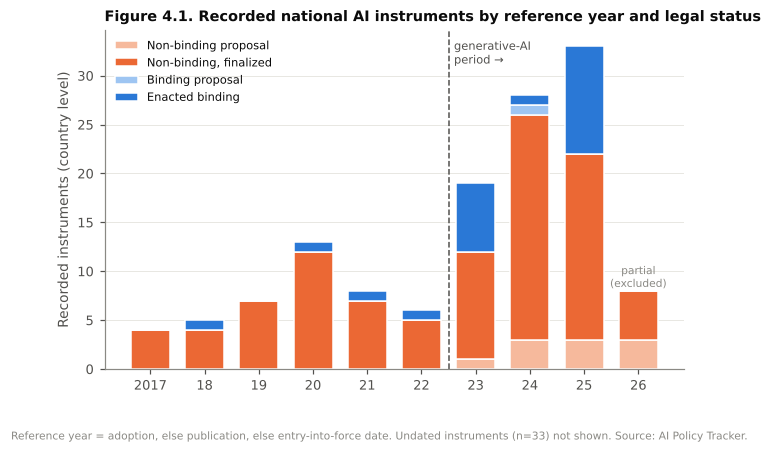

saved -> outputs/figures/Figure4_1_RQ4_instruments_by_reference_year.pdf


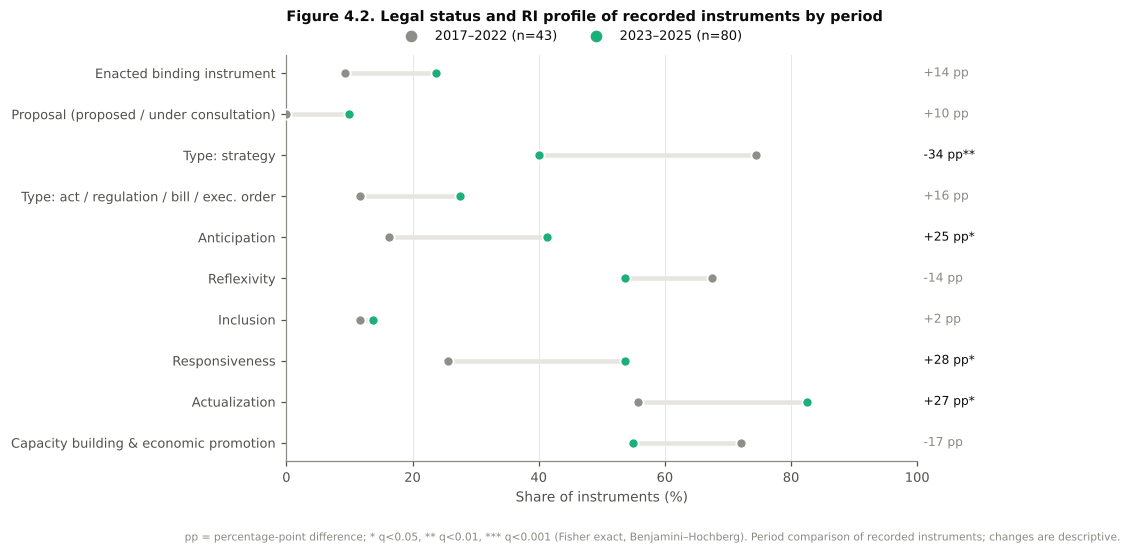

saved -> outputs/figures/Figure4_2_RQ4_profile_by_period.pdf


In [17]:
annual = pd.crosstab(inst.loc[inst.year >= 2017, "year"].astype(int), inst.loc[inst.year >= 2017, "legal_status3"])
annual = annual.reindex(columns=STATUS3, fill_value=0)
save_table(annual.reset_index(), "Table4_5_RQ4_annual_counts_by_legal_status")
fig, ax = plt.subplots(figsize=(6.8, 4.0))
yrs = annual.index.values; bottom = np.zeros(len(yrs))
ST_COL = {"Non-binding proposal": "#f6b99c", "Non-binding, finalized": COL["nonbinding"],
          "Other binding (not in force)": COL["none"], "Binding proposal": COL["draft"], "Enacted binding": COL["binding"]}
for st in STATUS3[::-1]:
    col = ST_COL[st]; v = annual[st].values
    ax.bar(yrs, v, bottom=bottom, width=0.72, color=col, label=st, edgecolor="white", linewidth=1)
    bottom += v
ax.axvline(2022.5, color=COL["ink2"], lw=1, ls="--")
ax.text(2022.6, bottom.max() * 1.02, "generative-AI\nperiod →", fontsize=7.5, color=COL["ink2"], va="top")
if yrs.max() > LAST_FULL_YEAR:
    ax.text(yrs.max(), bottom[-1] + 0.4, "partial\n(excluded)", ha="center", fontsize=7, color=COL["muted"])
ax.set_xticks(yrs); ax.set_xticklabels([str(y)[2:] if y != yrs[0] else str(y) for y in yrs])
ax.set_ylabel("Recorded instruments (country level)"); ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", fontsize=7.5)
ax.set_title("Figure 4.1. Recorded national AI instruments by reference year and legal status", loc="left", fontsize=9.5)
fig.text(0.0, -0.05, f"Reference year = adoption, else publication, else entry-into-force date. Undated instruments "
         f"(n={int(inst.year.isna().sum())}) not shown. Source: AI Policy Tracker.", fontsize=7, color=COL["muted"])
save_fig(fig, "Figure4_1_RQ4_instruments_by_reference_year")

show = ["enacted", "proposal", "type_strategy", "type_hard_law"] + DIM_CODES + ["cap_capacity"]
d = t4.set_index("code")
fig, ax = plt.subplots(figsize=(7.4, 4.8))
for k, c in enumerate(show):
    yy = -k; p0, p1 = d.loc[c, "pct_2017–2022"], d.loc[c, "pct_2023+"]
    ax.plot([p0, p1], [yy, yy], color=COL["grid"], lw=3, solid_capstyle="round", zorder=1)
    ax.scatter(p0, yy, s=44, color=COL["pre"], edgecolor="white", linewidth=1.2, zorder=3)
    ax.scatter(p1, yy, s=44, color=COL["post"], edgecolor="white", linewidth=1.2, zorder=3)
    q = d.loc[c, "q_bh"]
    ax.text(1.01, yy, f"{d.loc[c,'diff_pp']:+.0f} pp{stars(q)}", transform=mtrans.blended_transform_factory(ax.transAxes, ax.transData),
            va="center", fontsize=8, color=COL["ink"] if q < 0.05 else COL["muted"])
ax.set_yticks([-k for k in range(len(show))])
ax.set_yticklabels([lab4[c] for c in show])
ax.set_xlim(0, 100); ax.grid(axis="y", visible=False); ax.set_xlabel("Share of instruments (%)")
n0, n1 = (d4.period == "2017–2022").sum(), (d4.period == "2023+").sum()
ax.scatter([], [], color=COL["pre"], s=44, label=f"2017–2022 (n={n0})")
ax.scatter([], [], color=COL["post"], s=44, label=f"2023–{LAST_FULL_YEAR} (n={n1})")
ax.legend(loc="lower center", bbox_to_anchor=(0.45, 1.0), ncol=2)
ax.set_title("Figure 4.2. Legal status and RI profile of recorded instruments by period", loc="left", pad=22, fontsize=9.5)
fig.text(0.0, -0.04, "pp = percentage-point difference; * q<0.05, ** q<0.01, *** q<0.001 (Fisher exact, Benjamini–Hochberg). "
         "Period comparison of recorded instruments; changes are descriptive.", fontsize=7, color=COL["muted"])
save_fig(fig, "Figure4_2_RQ4_profile_by_period")

## Step 12 · Robustness checks (Table S3) and Figure 3.2
**What this cell does:** re-estimates the key quantity of each RQ under alternative specifications; within each RQ the **outcome and model terms are held constant** and listed explicitly:
- RQ1 – enacted binding vs finalized non-binding, unadjusted OR: (i) main, (ii) verified or high-confidence records, (iii) excluding strategies (instrument-mix check), (iv) non-binding group including proposals, (v) Tracker binding flag incl. binding proposals (labelled comparison);
- RQ2 – recorded strategy adoption, M2 GE odds ratio and M3 interaction LR test for GE, pre-period GE and Regulatory Quality;
- RQ3 – Stage 2 (enacted national binding measure, Firth, profile CIs) with *governance + EU membership* for GE, pre-period GE and RQ; *excluding EU members* (EU term dropped: constant); and the EU AI Act attributed to members (EU term dropped: it would perfectly predict the outcome) – the latter treats a single shared supranational act as 27 national measures and is reported only as a sensitivity;
- RQ4 – enacted binding share and RI dimensions, 2017–2025: main, verified/high-confidence records, finalized instruments only, including partial 2026.

Figure 3.2 plots the RQ3 rows. **Output:** *Table S3, Figure 3.2*.

,RQ,estimate,outcome_and_model_terms,specification,odds_ratio,ci_lo,ci_hi,p,N
0,RQ1,Ethics & values: binding vs non-binding (Fisher OR),binding status,main: enacted binding vs finalized non-binding,0.340,0.115,1.010,0.057,142
1,RQ1,Reflexivity: binding vs non-binding (Fisher OR),binding status,main: enacted binding vs finalized non-binding,0.386,0.157,0.948,0.039,142
2,RQ1,Risk assessment & classification: binding vs non-binding (Fisher OR),binding status,main: enacted binding vs finalized non-binding,6.203,2.370,16.236,<0.001,142
3,RQ1,Accountability & oversight: binding vs non-binding (Fisher OR),binding status,main: enacted binding vs finalized non-binding,4.237,1.696,10.585,0.003,142
4,RQ1,Obligations & enforcement: binding vs non-binding (Fisher OR),binding status,main: enacted binding vs finalized non-binding,15.682,5.648,43.543,<0.001,142
5,RQ1,Capacity building & economic promotion: binding vs non-binding (Fisher OR),binding status,main: enacted binding vs finalized non-binding,0.079,0.026,0.237,<0.001,142
6,RQ1,Ethics & values: binding vs non-binding (Fisher OR),binding status,verified or high-confidence records,0.339,0.113,1.011,0.053,137
7,RQ1,Reflexivity: binding vs non-binding (Fisher OR),binding status,verified or high-confidence records,0.392,0.157,0.977,0.056,137
8,RQ1,Risk assessment & classification: binding vs non-binding (Fisher OR),binding status,verified or high-confidence records,8.280,3.027,22.649,<0.001,137
9,RQ1,Accountability & oversight: binding vs non-binding (Fisher OR),binding status,verified or high-confidence records,4.686,1.836,11.961,0.002,137


saved -> outputs/tables/TableS3_robustness_checks.csv


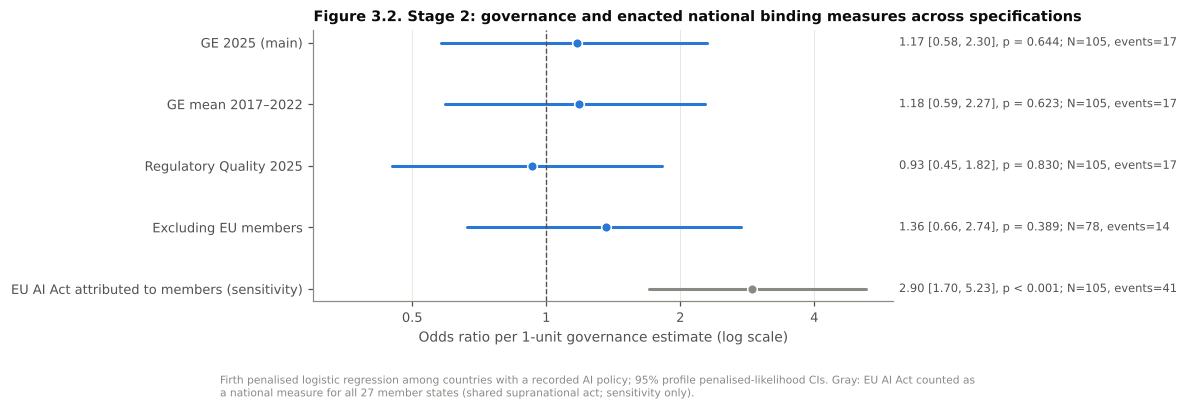

saved -> outputs/figures/Figure3_2_RQ3_stage2_odds_ratios_across_specifications.pdf


In [18]:
rob = []
key1 = ["ref_ethics", "dim_reflexivity", "ant_risk", "res_accountability", "act_obligation", "cap_capacity"]
hq = d1[(d1.review_status == "verified") | (d1.confidence_level == "high")]
nostrat = d1[d1.type3 != "Strategy"]
inclprop = inst[inst.enacted_binding | ~inst.is_binding].assign(
    grp=lambda x: np.where(x.enacted_binding, "Enacted binding", "Non-binding"))
flag = inst.assign(grp=np.where(inst.is_binding, "Enacted binding", "Non-binding"))
for spec, df in [("main: enacted binding vs finalized non-binding", d1), ("verified or high-confidence records", hq),
                 ("excluding strategies", nostrat), ("non-binding group incl. proposals", inclprop),
                 ("Tracker binding flag (incl. binding proposals) vs all non-binding", flag)]:
    for _, r in compare_binary(df.assign(grp=df.get("grp", np.where(df.enacted_binding, "Enacted binding", "Non-binding"))),
                               "grp", key1, "Enacted binding", "Non-binding").iterrows():
        rob.append(["RQ1", f"{r.label}: binding vs non-binding (Fisher OR)", "binding status", spec,
                    r.odds_ratio, r.or_ci_lo, r.or_ci_hi, r.p_fisher, int(r["N_Enacted binding"] + r["N_Non-binding"])])
for var, lab in GOV_MEASURES:
    s, f = rq2_models(var)
    ci = np.exp(f["M2"].conf_int().loc[var]); stat, df_, p_ = lr_test(f["M3"], f["M2"])
    rob.append(["RQ2", "Recorded strategy adoption: governance OR per 1-unit WGI (M2)", f"{var} + income", lab,
                np.exp(f["M2"].params[var]), ci[0], ci[1], f["M2"].pvalues[var], int(f["M2"].nobs)])
    rob.append(["RQ2", f"Governance × income interaction: LR test M3 vs M2 (χ²={stat:.2f}, df={df_})", f"{var} × income", lab,
                np.nan, np.nan, np.nan, p_, int(f["M3"].nobs)])
pol_c = cty[cty.has_any_policy].copy(); pol_c["eu"] = pol_c.eu_member.astype(int)
rq3_specs = [
    (f"GE {WGI_YEAR} (main)", pol_c, "binding_national", ["ge", "eu"]),
    ("GE mean 2017–2022", pol_c, "binding_national", ["ge_pre", "eu"]),
    (f"Regulatory Quality {WGI_YEAR}", pol_c, "binding_national", ["rq", "eu"]),
    ("Excluding EU members", pol_c[~pol_c.eu_member], "binding_national", ["ge"]),
    ("EU AI Act attributed to members (sensitivity)", pol_c, "binding_eu_adj", ["ge"]),
]
rq3_rows = []
for lab, df, outcome, preds in rq3_specs:
    r = run_firth(df.dropna(subset=[preds[0]]), outcome, preds, lab).iloc[1]
    rq3_rows.append([lab, r.odds_ratio, r.profile_ci_lo, r.profile_ci_hi, r.p_penalised_LR, int(r.N), int(r.events)])
    rob.append(["RQ3", "Stage 2: enacted binding among countries with a recorded policy (Firth OR, profile CI)",
                " + ".join(preds) + f" → {outcome}", lab, r.odds_ratio, r.profile_ci_lo, r.profile_ci_hi, r.p_penalised_LR, int(r.N)])
key4 = ["enacted", "dim_anticipation", "dim_responsiveness", "cap_capacity"]
hq4 = d4[(d4.review_status == "verified") | (d4.confidence_level == "high")]
for spec, df in [(f"2017–{LAST_FULL_YEAR} (main)", d4), ("verified or high-confidence records", hq4),
                 ("finalized instruments only (proposals excluded)", d4fin),
                 (f"2017–{int(inst.year.max())} incl. partial year", d4all)]:
    for _, r in compare_binary(df, "period", key4, "2023+", "2017–2022", labels=lab4).iterrows():
        rob.append(["RQ4", f"{r.label}: 2023+ vs 2017–2022 (Fisher OR)", "period", spec,
                    r.odds_ratio, r.or_ci_lo, r.or_ci_hi, r.p_fisher, int(r["N_2023+"] + r["N_2017–2022"])])
ts3 = pd.DataFrame(rob, columns=["RQ", "estimate", "outcome_and_model_terms", "specification", "odds_ratio", "ci_lo", "ci_hi", "p", "N"])
save_table(ts3.round(3).assign(p=ts3.p.map(fmt_p)), "TableS3_robustness_checks")

f32 = pd.DataFrame(rq3_rows, columns=["spec", "or", "lo", "hi", "p", "N", "events"])
fig, ax = plt.subplots(figsize=(6.8, 3.2))
for i, r in f32.iloc[::-1].reset_index(drop=True).iterrows():
    col = COL["muted"] if "attributed" in r.spec else COL["binding"]
    ax.plot([r.lo, r.hi], [i, i], color=col, lw=2, solid_capstyle="round")
    ax.scatter(r["or"], i, s=40, color=col, zorder=3, edgecolor="white")
    ax.text(1.01, i, f"{r['or']:.2f} [{r.lo:.2f}, {r.hi:.2f}], {pstr(r.p)}; N={r.N}, events={r.events}",
            transform=mtrans.blended_transform_factory(ax.transAxes, ax.transData), va="center", fontsize=7.5, color=COL["ink2"])
ax.axvline(1, color=COL["ink2"], lw=0.9, ls="--")
ax.set_xscale("log"); ax.set_yticks(range(len(f32))); ax.set_yticklabels(f32.spec[::-1])
ax.xaxis.set_major_locator(mpl.ticker.FixedLocator([0.25, 0.5, 1, 2, 4, 8]))
ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlim(min(0.3, f32.lo.min() * 0.85), max(6, f32.hi.max() * 1.15))
ax.set_xlabel("Odds ratio per 1-unit governance estimate (log scale)"); ax.grid(axis="y", visible=False)
ax.set_title("Figure 3.2. Stage 2: governance and enacted national binding measures across specifications",
             loc="left", fontsize=9.5)
fig.text(0.0, -0.16, "Firth penalised logistic regression among countries with a recorded AI policy; 95% profile penalised-likelihood CIs. "
         "Gray: EU AI Act counted as\na national measure for all 27 member states (shared supranational act; sensitivity only).",
         fontsize=7, color=COL["muted"])
save_fig(fig, "Figure3_2_RQ3_stage2_odds_ratios_across_specifications")

## Step 13 · Key findings (generated from the results above)
**What this cell does:** writes a short, data-driven summary per research question; every number is pulled from the tables computed above. Wording is restricted to associations between governance indicators and *recorded* instruments.

In [19]:
t1i, t4i = t1.set_index("code"), t4.set_index("code")
t13i = t13.set_index("code")
def line(c, tab, g1, g0, adj=None):
    r = tab.loc[c]
    s = f"{r.label}: {r[f'pct_{g1}']:.0f}% vs {r[f'pct_{g0}']:.0f}% (OR {r.odds_ratio:.2f}, {pstr(r.q_bh, 'q')}"
    if adj is not None and c in adj.index:
        a = adj.loc[c]
        s += ("; clustered & length-adjusted: not estimable" if pd.isna(a.adj_odds_ratio)
              else f"; clustered & length-adjusted OR {a.adj_odds_ratio:.2f}, {pstr(a.q_bh, 'q')}")
    return s + ")"

st1 = t3b[t3b.model.str.startswith("Stage 1:") & (t3b.term == "ge")].iloc[0]
st2 = t3b[t3b.model.str.startswith("Stage 2 (main)") & (t3b.term == "ge")].iloc[0]
eu_r = f32[f32.spec.str.startswith("EU AI Act")].iloc[0]
slope = t2c[(t2c.model == "M3 income-specific") & (t2c.governance_measure.str.contains("main"))]
lrs = t2c[t2c.model == "LR test M3 vs M2"]
rel = t12[(t12.comparison == "Dictionary vs LLM-assisted rater")]
rel_sub, rel_dim = rel[rel.level == "Sub-theme"], rel[rel.level == "Dimension"]
xt_ = xt.drop(index="Total", columns="Total")
no_strat_binding = int(xt_.loc["No recorded adopted strategy", "Enacted national binding measure"]) if "No recorded adopted strategy" in xt_.index else 0

def kap_summary(comp):
    r = t12[(t12.comparison == comp) & (t12.level == "Sub-theme")]
    return f"median κ = {r.cohen_kappa.median():.2f} (range {r.cohen_kappa.min():.2f}–{r.cohen_kappa.max():.2f}); {int((r.cohen_kappa >= 0.70).sum())} of {len(r)} sub-themes ≥ 0.70"
hum_txt = (f"Human validation complete: coder A vs B {kap_summary('Coder A vs coder B (human)')}; dictionary vs consensus {kap_summary('Dictionary vs human consensus')}."
           if HUMAN_DONE else "Deviation from the proposal: the planned two-coder human validation was not carried out; reliability evidence comes from the LLM-assisted blind rater only, and codes with κ < 0.70 are reported as a limitation.")
t44ai = t44a.set_index("code")
txt = f'''
**Coding reliability (Table 1.2).** Dictionary vs LLM-assisted blind rater on the 40-summary validation sample:
median κ across sub-themes = {rel_sub.cohen_kappa.median():.2f} (range {rel_sub.cohen_kappa.min():.2f}–{rel_sub.cohen_kappa.max():.2f});
{int((rel_sub.cohen_kappa >= 0.70).sum())} of {len(rel_sub)} sub-themes meet κ ≥ 0.70; dimension-level κ = {", ".join(f"{r.label} {r.cohen_kappa:.2f}" for r in rel_dim.itertuples())}.
{hum_txt}

**RQ1 – RI profile (enacted binding vs finalized non-binding; all proposals excluded). Unadjusted Fisher tests, then country-clustered models adjusted for summary length.**
- {line("ref_ethics", t1i, "Enacted binding", "Non-binding", t13i)}
- {line("dim_reflexivity", t1i, "Enacted binding", "Non-binding", t13i)}
- {line("ant_risk", t1i, "Enacted binding", "Non-binding", t13i)}
- {line("res_transparency", t1i, "Enacted binding", "Non-binding", t13i)}
- {line("res_accountability", t1i, "Enacted binding", "Non-binding", t13i)}
- {line("act_obligation", t1i, "Enacted binding", "Non-binding", t13i)}
- {line("cap_capacity", t1i, "Enacted binding", "Non-binding", t13i)}

**RQ2 – GE and recorded strategy adoption.** Adopters' mean GE {t2a.loc[0,'GE_mean_adopters']:.2f} vs {t2a.loc[0,'GE_mean_non_adopters']:.2f}
(Cliff's δ = {t2a.loc[0,'cliffs_delta']:.2f}, {pstr(t2a.loc[0,'p_mannwhitney'])}). Income-specific OR per 1-unit GE (model M3):
''' + "\n".join(f"- {r.income_group}: OR {r.odds_ratio_per_1unit:.2f} [{r.ci_lo:.2f}, {r.ci_hi:.2f}], {pstr(r.p)}" for r in slope.itertuples()) + "\n" + \
"\n".join(f"- GE × income LR test, {r.governance_measure}: χ² = {r.LR_chi2:.2f}, df = {int(r.LR_df)}, {pstr(r.p)}" for r in lrs.itertuples()) + f'''

**RQ3 – Recorded policies and enacted national binding measures (cross-sectional).** Stage 1 (any recorded policy): OR per 1-unit GE = {st1.odds_ratio:.2f}
[{st1.profile_ci_lo:.2f}, {st1.profile_ci_hi:.2f}], {pstr(st1.p_penalised_LR)}. Stage 2 (enacted national binding measure among countries with a recorded policy, GE + EU, {int(st2.events)} events in {int(st2.N)} countries):
OR = {st2.odds_ratio:.2f} [{st2.profile_ci_lo:.2f}, {st2.profile_ci_hi:.2f}], {pstr(st2.p_penalised_LR)} – the interval is wide, so the data are compatible with both no association and a sizeable positive one.
Strategy concreteness vs GE: ρ = {t3c.iloc[0].spearman_rho_with_GE:.2f}, {pstr(t3c.iloc[0].p)}. {no_strat_binding} countries with an enacted national binding measure have no recorded adopted strategy (Table 3.4).
Sensitivity: counting the EU AI Act as a national measure for all 27 member states gives OR = {eu_r['or']:.2f} [{eu_r.lo:.2f}, {eu_r.hi:.2f}], {pstr(eu_r.p)}; this treats one shared supranational act as 27 national measures and is not the main specification.

**RQ4 – Recorded instruments 2023–{LAST_FULL_YEAR} vs 2017–2022 (descriptive comparison of the recorded instrument mix).**
- {line("enacted", t4i, "2023+", "2017–2022", t44ai)}
- {line("proposal", t4i, "2023+", "2017–2022", t44ai)}
- {line("dim_responsiveness", t4i, "2023+", "2017–2022", t44ai)}
- {line("dim_anticipation", t4i, "2023+", "2017–2022", t44ai)}
- {line("cap_capacity", t4i, "2023+", "2017–2022", t44ai)}
- Undated instruments excluded: {int(inst.year.isna().sum())} of {len(inst)} (Table 4.3).

*Coding basis: dictionary-based coding of Tracker policy summaries (Table S2); validation: LLM-assisted blind rater{" and two human coders with adjudicated consensus" if HUMAN_DONE else " (human double coding planned in the proposal not carried out)"}.*
'''
display(Markdown(txt))
(OUT / "key_findings.md").write_text(txt, encoding="utf-8")


**Coding reliability (Table 1.2).** Dictionary vs LLM-assisted blind rater on the 40-summary validation sample:
median κ across sub-themes = 0.73 (range 0.55–0.95);
7 of 13 sub-themes meet κ ≥ 0.70; dimension-level κ = Anticipation 0.75, Reflexivity 0.85, Inclusion 0.66, Responsiveness 0.85, Actualization 0.78.
Deviation from the proposal: the planned two-coder human validation was not carried out; reliability evidence comes from the LLM-assisted blind rater only, and codes with κ < 0.70 are reported as a limitation.

**RQ1 – RI profile (enacted binding vs finalized non-binding; all proposals excluded). Unadjusted Fisher tests, then country-clustered models adjusted for summary length.**
- Ethics & values: 17% vs 40% (OR 0.34, q = 0.102; clustered & length-adjusted OR 0.66, q = 0.607)
- Reflexivity: 39% vs 63% (OR 0.39, q = 0.078; clustered & length-adjusted OR 0.55, q = 0.491)
- Risk assessment & classification: 48% vs 13% (OR 6.20, q = 0.002; clustered & length-adjusted OR 3.17, q = 0.142)
- Transparency & explainability: 43% vs 18% (OR 3.56, q = 0.029; clustered & length-adjusted OR 1.88, q = 0.491)
- Accountability & oversight: 52% vs 20% (OR 4.24, q = 0.009; clustered & length-adjusted OR 2.14, q = 0.300)
- Obligations & enforcement: 65% vs 10% (OR 15.68, q < 0.001; clustered & length-adjusted OR 9.06, q = 0.005)
- Capacity building & economic promotion: 17% vs 75% (OR 0.08, q < 0.001; clustered & length-adjusted OR 0.12, q = 0.005)

**RQ2 – GE and recorded strategy adoption.** Adopters' mean GE 0.62 vs -0.35
(Cliff's δ = 0.58, p < 0.001). Income-specific OR per 1-unit GE (model M3):
- Low & lower-middle: OR 31.41 [4.90, 201.24], p < 0.001
- Upper-middle: OR 5.01 [1.17, 21.47], p = 0.030
- High: OR 2.00 [0.82, 4.87], p = 0.127
- GE × income LR test, GE 2025 (main): χ² = 8.96, df = 2, p = 0.011
- GE × income LR test, GE mean 2017–2022: χ² = 9.25, df = 2, p = 0.010
- GE × income LR test, Regulatory Quality 2025: χ² = 6.72, df = 2, p = 0.035

**RQ3 – Recorded policies and enacted national binding measures (cross-sectional).** Stage 1 (any recorded policy): OR per 1-unit GE = 4.23
[2.77, 6.84], p < 0.001. Stage 2 (enacted national binding measure among countries with a recorded policy, GE + EU, 17 events in 105 countries):
OR = 1.17 [0.58, 2.30], p = 0.644 – the interval is wide, so the data are compatible with both no association and a sizeable positive one.
Strategy concreteness vs GE: ρ = 0.31, p = 0.007. 6 countries with an enacted national binding measure have no recorded adopted strategy (Table 3.4).
Sensitivity: counting the EU AI Act as a national measure for all 27 member states gives OR = 2.90 [1.70, 5.23], p < 0.001; this treats one shared supranational act as 27 national measures and is not the main specification.

**RQ4 – Recorded instruments 2023–2025 vs 2017–2022 (descriptive comparison of the recorded instrument mix).**
- Enacted binding instrument: 24% vs 9% (OR 2.78, q = 0.084; clustered & length-adjusted OR 2.14, q = 0.324)
- Proposal (proposed / under consultation): 10% vs 0% (OR 10.20, q = 0.084; clustered & length-adjusted: not estimable)
- Responsiveness: 54% vs 26% (OR 3.28, q = 0.015; clustered & length-adjusted OR 2.55, q = 0.177)
- Anticipation: 41% vs 16% (OR 3.43, q = 0.015; clustered & length-adjusted OR 2.66, q = 0.177)
- Capacity building & economic promotion: 55% vs 72% (OR 0.48, q = 0.098; clustered & length-adjusted OR 0.63, q = 0.334)
- Undated instruments excluded: 33 of 164 (Table 4.3).

*Coding basis: dictionary-based coding of Tracker policy summaries (Table S2); validation: LLM-assisted blind rater (human double coding planned in the proposal not carried out).*


3671

## Step 14 · Export: manifest and zip of all figures and tables
**What this cell does:** lists every saved figure (PDF/PNG) and table (CSV), writes a manifest linking each file to its research question with its SHA-256 checksum, and packs the `outputs` folder into `ai_ri_policy_results.zip`.
**Methodological step:** packaging the results for the manuscript and supplementary material.

In [20]:
def rq_of(name):
    m = re.search(r"(?:RQ|Table|Figure)(\d)", name)
    return f"RQ{m.group(1)}" if m and not name.startswith("TableS") else "Supplementary"

files = sorted(p for p in OUT.rglob("*") if p.is_file() and p.name != "manifest.csv")
manifest = pd.DataFrame({
    "file": [str(p.relative_to(OUT)) for p in files],
    "type": [p.suffix.lstrip(".").upper() for p in files],
    "research_question": [rq_of(p.name) for p in files],
    "size_kb": [round(p.stat().st_size / 1024, 1) for p in files],
    "sha256": [sha256(p) for p in files],
})
save_table(manifest, "manifest", show=False)
print(f"{len(manifest)} files; figures: {(manifest.type == 'PDF').sum()}, tables: {(manifest.type == 'CSV').sum()}")

zip_base = OUT.parent / "ai_ri_policy_results"
zip_path = shutil.make_archive(str(zip_base), "zip", root_dir=OUT.parent, base_dir=OUT.name)
with zipfile.ZipFile(zip_path) as z:
    print(f"Created {zip_path} with {len(z.namelist())} entries ({Path(zip_path).stat().st_size/1024:.0f} KB)")

saved -> outputs/tables/manifest.csv
50 files; figures: 8, tables: 32
Created /home/claude/run12/ai_ri_policy_results.zip with 54 entries (2509 KB)
